# Insurance Claim Prediction (Safe Driver) — Porto Seguro

**Course:** Programming for Data Analysis and Database · Applied Artificial Intelligence (MSc) · Topic 40 · Insurance Claim Prediction

**Team:** Bezhenar Pavel · Abay Zhenis · Alenov Abay · AAI-2604

**Task.** Predict whether a policyholder will file an insurance claim next year (`target = 1`).
**Data.** [Porto Seguro Safe Driver Prediction](https://www.kaggle.com/competitions/porto-seguro-safe-driver-prediction) — 595,212 policyholders, 57 anonymised features (`ps_ind_*`, `ps_reg_*`, `ps_car_*`, `ps_calc_*`), missing values coded as `-1`, ~3.6 % positives.
**Metrics.** Normalised Gini (= 2·ROC-AUC − 1, the competition metric), ROC-AUC, PR-AUC, log-loss, Brier score.

| Part | Content | Main outputs (re-used by the next part) |
|---|---|---|
| **1 · Data engineering, audit, SQL & EDA** | zip upload + extraction, chunked load + dtype optimisation, CSV vs Parquet, data-quality audit, cleaning, SQLite schema + ER diagram + 10 SQL queries, EDA + hypothesis tests | `data/processed/train_clean.parquet`, `porto.db`, `feature_dictionary.parquet` |
| **2 · Modelling & comparison** | leakage-free split, feature-set ablation, baselines, Random Forest / HistGB / LightGBM / XGBoost, Optuna tuning with CV, bootstrap CIs, blend | `models/*.joblib`, `reports/model_comparison.parquet`, `experiments` table in SQLite |
| **3 · Interpretation, extensions & deployment** | permutation importance + SHAP, error analysis, calibration, thresholds/cost, external dataset (freMTPL2), Kaggle submission, interactive console menu | `models/safe_driver_bundle.joblib`, `submission.csv`, figures |

> Each part starts by re-loading what it needs from disk, so the three parts can be run (or split into three notebooks for GitHub) independently once Part 1 has produced the processed data.

**How to run in Colab:** `Runtime → Run all`. When prompted in §1.1, upload `porto-seguro-safe-driver-prediction.zip` (the Kaggle download); the CSVs are extracted automatically.

## 0 · Project modules (requirement 8 — modular code)
The cells below write the helper modules to `src/` (they are also committed in the repository). The notebook only *uses* these functions; all heavy logic is in importable, testable `.py` files.

In [ ]:
import os
os.makedirs("src", exist_ok=True)

In [ ]:
%%writefile src/__init__.py
"""Porto Seguro Safe Driver project: helper modules."""

Overwriting src/__init__.py


In [ ]:
%%writefile src/config.py
"""Shared configuration: paths, seeds and run switches (edit here or override in the notebook)."""
from pathlib import Path

SEED = 42
ROOT = Path.cwd()
DATA_RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports"
FIGURES = ROOT / "figures"
DB_PATH = PROCESSED / "porto.db"
for _p in (DATA_RAW, PROCESSED, MODELS, REPORTS, FIGURES, REPORTS / "sql"):
    _p.mkdir(parents=True, exist_ok=True)

# ---- run switches ---------------------------------------------------------
ZIP_NAME = "porto-seguro-safe-driver-prediction.zip"  # the Kaggle download you upload in Colab
TEST_SIZE = 0.20        # stratified hold-out share
CV_FOLDS = 3            # folds used for tuning / ablation inside the training part
N_TRIALS_LGBM = 20      # Optuna trials (more = better, slower)
N_TRIALS_XGB = 12
RUN_EXTERNAL = True     # Part 3: external dataset (freMTPL2freq from OpenML)
MAKE_SUBMISSION = True  # Part 3: refit on all data and write submission.csv (needs test.csv)
RUN_INTERACTIVE = True  # Part 3: True opens the live console menu (uses input())


def save_fig(name: str, dpi: int = 150) -> None:
    """Save the current matplotlib figure into figures/."""
    import matplotlib.pyplot as plt
    plt.savefig(FIGURES / f"{name}.png", dpi=dpi, bbox_inches="tight")

Overwriting src/config.py


In [ ]:
%%writefile src/data_utils.py
"""Data loading, dtype optimisation, missing-value handling and feature helpers."""
from __future__ import annotations

import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score

MISSING_CODE = -1      # Porto Seguro encodes "missing" as -1 in every column
TARGET = "target"
ID_COL = "id"

FAMILY_DESCRIPTIONS = {
    "ind": "Individual (driver) attributes",
    "reg": "Regional / area attributes",
    "car": "Vehicle attributes",
    "calc": "Calculated insurer features (anonymised)",
    "other": "Engineered features",
}


# ----------------------------------------------------------------------------
# Memory helpers
# ----------------------------------------------------------------------------
def mem_mb(df: pd.DataFrame) -> float:
    """Deep memory usage of a DataFrame in MB."""
    return float(df.memory_usage(deep=True).sum() / 1024 ** 2)


def optimize_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    """Downcast integers to the smallest int type and floats to float32."""
    out = df.copy()
    for col in out.columns:
        s = out[col]
        if pd.api.types.is_integer_dtype(s):
            out[col] = pd.to_numeric(s, downcast="integer")
        elif pd.api.types.is_float_dtype(s):
            out[col] = s.astype("float32")
    return out


def load_csv_chunked(path, chunksize: int = 100_000, verbose: bool = True) -> pd.DataFrame:
    """Read a large CSV in chunks, optimising dtypes chunk by chunk.

    Peak memory stays close to (compact result + one raw chunk) instead of
    (raw full frame). Raises a readable error if the file is missing.
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"CSV not found: {path}")
    chunks, t0 = [], time.perf_counter()
    for i, chunk in enumerate(pd.read_csv(path, chunksize=chunksize)):
        chunks.append(optimize_dtypes(chunk))
        if verbose:
            print(f"  chunk {i + 1}: {len(chunk):>7,} rows", end="\r")
    df = optimize_dtypes(pd.concat(chunks, ignore_index=True))  # unify dtypes across chunks
    if verbose:
        print(f"\nLoaded {len(df):,} rows x {df.shape[1]} cols in {time.perf_counter() - t0:.1f}s "
              f"({mem_mb(df):.1f} MB)")
    return df


# ----------------------------------------------------------------------------
# Column bookkeeping
# ----------------------------------------------------------------------------
def classify_columns(columns) -> dict[str, list[str]]:
    """Split Porto Seguro feature names into bin / cat / num lists by suffix."""
    groups = {"bin": [], "cat": [], "num": []}
    for c in columns:
        if c in (ID_COL, TARGET):
            continue
        if c.endswith("_bin"):
            groups["bin"].append(c)
        elif c.endswith("_cat"):
            groups["cat"].append(c)
        else:
            groups["num"].append(c)
    return groups


def feature_family(col: str) -> str:
    """'ps_car_13' -> 'car'; engineered columns -> 'other'."""
    parts = col.split("_")
    return parts[1] if col.startswith("ps_") and len(parts) > 2 else "other"


def calc_columns(columns) -> list[str]:
    return [c for c in columns if c.startswith("ps_calc_")]


# ----------------------------------------------------------------------------
# Missing values
# ----------------------------------------------------------------------------
def count_missing_codes(df: pd.DataFrame) -> pd.Series:
    """Number of -1 codes per feature (only features that have any)."""
    feats = [c for c in df.columns if c not in (ID_COL, TARGET)]
    counts = (df[feats] == MISSING_CODE).sum()
    return counts[counts > 0].sort_values(ascending=False)


def replace_missing_codes(df: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, int]]:
    """Replace -1 with NaN (columns with missing values become float32)."""
    out, report = df.copy(), {}
    for col in [c for c in out.columns if c not in (ID_COL, TARGET)]:
        mask = out[col] == MISSING_CODE
        n = int(mask.sum())
        if n:
            out[col] = out[col].astype("float32").mask(mask)
            report[col] = n
    return out, report


# ----------------------------------------------------------------------------
# Feature engineering (row-wise, stateless -> cannot leak across the split)
# ----------------------------------------------------------------------------
ENGINEERED = ["n_missing", "ind_bin_sum", "car13_x_reg03", "reg_sum"]


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add engineered features. Needs NaN (not -1) as the missing marker."""
    out = df.copy()
    raw = [c for c in out.columns if c not in (ID_COL, TARGET) and c not in ENGINEERED]
    out["n_missing"] = out[raw].isna().sum(axis=1).astype("int8")
    ind_bin = [c for c in raw if c.startswith("ps_ind_") and c.endswith("_bin")]
    out["ind_bin_sum"] = out[ind_bin].sum(axis=1).astype("int8")
    out["car13_x_reg03"] = (out["ps_car_13"] * out["ps_reg_03"]).astype("float32")
    out["reg_sum"] = (out["ps_reg_01"] + out["ps_reg_02"] + out["ps_reg_03"]).astype("float32")
    return out


def select_feature_set(df: pd.DataFrame, name: str) -> list[str]:
    """Return the column list for a named feature set."""
    base = [c for c in df.columns if c not in (ID_COL, TARGET) and c not in ENGINEERED]
    if name == "raw_all":
        return base
    if name == "drop_calc":
        return [c for c in base if not c.startswith("ps_calc_")]
    if name == "drop_calc+engineered":
        return [c for c in base if not c.startswith("ps_calc_")] + [c for c in ENGINEERED if c in df.columns]
    raise ValueError(f"Unknown feature set: {name}")


# ----------------------------------------------------------------------------
# Univariate signal (used for the feature dictionary and EDA)
# ----------------------------------------------------------------------------
def feature_signal(s: pd.Series, y: pd.Series, max_groups: int = 100, n_folds: int = 5,
                   seed: int = 42) -> tuple[float, float]:
    """Univariate normalised Gini (out-of-fold) and chi-square p-value of one feature vs target.

    Each distinct value (or quantile bin if > max_groups values; the bins use only X, not y) is
    mapped to its target rate **estimated on the other folds**; the Gini is 2*AUC-1 of that score.
    Cross-fitting removes the in-sample optimism that would otherwise favour high-cardinality
    features, so pure-noise features land near 0.
    """
    from sklearn.model_selection import KFold
    x = s.astype("float64")
    if x.nunique() > max_groups:
        x = pd.Series(pd.qcut(x, max_groups, labels=False, duplicates="drop"), index=x.index)
    key = x.fillna(-999.0).reset_index(drop=True)
    yy = y.reset_index(drop=True)
    score = np.full(len(yy), yy.mean())
    for tr, va in KFold(n_folds, shuffle=True, random_state=seed).split(key):
        rate = yy.iloc[tr].groupby(key.iloc[tr]).mean()
        score[va] = key.iloc[va].map(rate).fillna(yy.iloc[tr].mean()).to_numpy()
    gini = 2 * roc_auc_score(yy, score) - 1
    table = pd.crosstab(key, yy)
    p = stats.chi2_contingency(table)[1] if table.shape[0] > 1 else 1.0
    return float(gini), float(p)


def build_feature_dictionary(df: pd.DataFrame) -> pd.DataFrame:
    """One row per raw feature: family, kind, missingness, cardinality, signal."""
    groups = classify_columns(df.columns)
    kind_of = {c: k for k, cols in groups.items() for c in cols}
    y = df[TARGET]
    rows = []
    for col in [c for c in df.columns if c not in (ID_COL, TARGET)]:
        gini, p = feature_signal(df[col], y)
        rows.append({
            "feature": col, "family": feature_family(col), "kind": kind_of[col],
            "n_missing": int(df[col].isna().sum()),
            "pct_missing": round(100 * df[col].isna().mean(), 3),
            "n_unique": int(df[col].nunique()),
            "univariate_gini": round(gini, 5), "chi2_pvalue": p,
        })
    return pd.DataFrame(rows)

Overwriting src/data_utils.py


In [ ]:
%%writefile src/metrics.py
"""Evaluation helpers: Gini, PR-AUC, bootstrap CIs, lift tables."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             roc_auc_score)


def gini_normalized(y_true, y_score) -> float:
    """Normalised Gini = 2*AUC - 1 (the Kaggle competition metric)."""
    return 2 * roc_auc_score(y_true, y_score) - 1


def evaluate_predictions(y_true, proba) -> dict:
    """All probability-based metrics used in the comparison tables."""
    proba = np.asarray(proba)
    return {
        "roc_auc": roc_auc_score(y_true, proba),
        "gini": gini_normalized(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "log_loss": log_loss(y_true, np.clip(proba, 1e-7, 1 - 1e-7)),
        "brier": brier_score_loss(y_true, proba),
    }


def bootstrap_auc_ci(y_true, proba, n_boot: int = 200, seed: int = 42, alpha: float = 0.05):
    """Percentile bootstrap CI for ROC-AUC. Returns (low, high)."""
    y, p = np.asarray(y_true), np.asarray(proba)
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return tuple(np.quantile(aucs, [alpha / 2, 1 - alpha / 2]))


def paired_bootstrap_diff(y_true, p_new, p_old, n_boot: int = 200, seed: int = 42):
    """Bootstrap the AUC difference (new - old) on the same resamples."""
    y, a, b = np.asarray(y_true), np.asarray(p_new), np.asarray(p_old)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        diffs.append(roc_auc_score(y[idx], a[idx]) - roc_auc_score(y[idx], b[idx]))
    diffs = np.array(diffs)
    return float(diffs.mean()), tuple(np.quantile(diffs, [0.025, 0.975])), float((diffs <= 0).mean())


def lift_table(y_true, proba, n_bins: int = 10) -> pd.DataFrame:
    """Decile table, bin 1 = highest predicted risk."""
    df = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(proba)})
    df["bin"] = pd.qcut(df["p"].rank(method="first", ascending=False), n_bins, labels=False) + 1
    base = df["y"].mean()
    t = df.groupby("bin").agg(n=("y", "size"), claims=("y", "sum"), mean_pred=("p", "mean")).reset_index()
    t["claim_rate"] = t["claims"] / t["n"]
    t["lift"] = t["claim_rate"] / base
    t["cum_capture"] = t["claims"].cumsum() / t["claims"].sum()
    return t


def confusion_at_threshold(y_true, proba, threshold: float) -> dict:
    """Confusion counts and precision/recall/F1 at a probability threshold."""
    y, pred = np.asarray(y_true), (np.asarray(proba) >= threshold).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"threshold": float(threshold), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": prec, "recall": rec, "f1": f1, "flagged_pct": 100 * pred.mean()}

Overwriting src/metrics.py


In [ ]:
%%writefile src/modeling.py
"""Pipelines, timing helpers and cross-validated hyper-parameter tuning."""
from __future__ import annotations

import os
import tempfile
import time

import joblib
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from .data_utils import classify_columns


# ----------------------------------------------------------------------------
# Preprocessing
# ----------------------------------------------------------------------------
def build_preprocessor(kind: str, columns: list[str]) -> ColumnTransformer:
    """ColumnTransformer for one of three model families.

    kind = 'linear'      : impute + scale numerics, one-hot categoricals
    kind = 'tree_nan'    : pass-through, NaN handled natively (LightGBM/XGBoost/HistGB)
    kind = 'tree_impute' : constant -1 imputation (sklearn RandomForest)
    """
    g = classify_columns(columns)
    num, cat, binary = g["num"], g["cat"], g["bin"]
    if kind == "linear":
        ct = ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                              ("sc", StandardScaler())]), num),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=-1)),
                              ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=200))]), cat),
            ("bin", SimpleImputer(strategy="most_frequent"), binary),
        ])
    elif kind == "tree_nan":
        ct = ColumnTransformer([("all", "passthrough", num + cat + binary)],
                               verbose_feature_names_out=False)
        ct.set_output(transform="pandas")
    elif kind == "tree_impute":
        ct = ColumnTransformer([("all", SimpleImputer(strategy="constant", fill_value=-1),
                                 num + cat + binary)], verbose_feature_names_out=False)
        ct.set_output(transform="pandas")
    else:
        raise ValueError(f"Unknown preprocessor kind: {kind}")
    return ct


def make_pipeline(model, kind: str, columns: list[str]) -> Pipeline:
    return Pipeline([("prep", build_preprocessor(kind, columns)), ("model", model)])


# ----------------------------------------------------------------------------
# Timing / size
# ----------------------------------------------------------------------------
def fit_timed(pipe, X, y):
    t0 = time.perf_counter()
    pipe.fit(X, y)
    return pipe, time.perf_counter() - t0


def predict_timed(pipe, X, n_ref: int = 1000):
    """Return (proba, milliseconds per 1000 rows)."""
    t0 = time.perf_counter()
    proba = pipe.predict_proba(X)[:, 1]
    elapsed = time.perf_counter() - t0
    return proba, 1000 * elapsed * n_ref / len(X)


def model_size_mb(obj) -> float:
    """Serialised size of an object (joblib, compress=0) in MB."""
    with tempfile.TemporaryDirectory() as d:
        path = os.path.join(d, "m.joblib")
        joblib.dump(obj, path, compress=0)
        return os.path.getsize(path) / 1024 ** 2


def make_cv_splits(X, y, n_splits: int = 3, seed: int = 42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(skf.split(X, y))


# ----------------------------------------------------------------------------
# Cross-validated boosting (native cv with early stopping)
# ----------------------------------------------------------------------------
def lgbm_cv(params: dict, X, y, splits, max_rounds: int = 2000, patience: int = 100, seed: int = 42):
    """Return (mean_auc, std_auc, best_rounds) from lightgbm.cv."""
    import lightgbm as lgb
    p = {"objective": "binary", "metric": "auc", "verbosity": -1, "seed": seed, **params}
    res = lgb.cv(p, lgb.Dataset(X, label=y), num_boost_round=max_rounds, folds=splits,
                 callbacks=[lgb.early_stopping(patience, verbose=False)])
    mean_key = next(k for k in res if k.endswith("auc-mean"))
    std_key = next(k for k in res if k.endswith("auc-stdv"))
    best = int(np.argmax(res[mean_key]))
    return float(res[mean_key][best]), float(res[std_key][best]), best + 1


def xgb_cv(params: dict, X, y, splits, max_rounds: int = 2000, patience: int = 100, seed: int = 42):
    """Return (mean_auc, std_auc, best_rounds) from xgboost.cv."""
    import xgboost as xgb
    p = {"objective": "binary:logistic", "eval_metric": "auc", "tree_method": "hist",
         "seed": seed, **params}
    res = xgb.cv(p, xgb.DMatrix(X, label=y), num_boost_round=max_rounds, folds=splits,
                 early_stopping_rounds=patience, verbose_eval=False)
    best = int(res["test-auc-mean"].values.argmax())
    return (float(res["test-auc-mean"].iloc[best]), float(res["test-auc-std"].iloc[best]), best + 1)


# ----------------------------------------------------------------------------
# Optuna studies
# ----------------------------------------------------------------------------
def lgbm_space(trial) -> dict:
    return {
        "learning_rate": 0.05,
        "num_leaves": trial.suggest_int("num_leaves", 8, 64),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 500, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
    }


def xgb_space(trial) -> dict:
    return {
        "learning_rate": 0.05,
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5.0, log=True),
    }


def run_study(kind: str, X, y, splits, n_trials: int = 20, seed: int = 42):
    """Tune 'lgbm' or 'xgb'. Returns (best_params, best_rounds, study)."""
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    space, cv_fn = (lgbm_space, lgbm_cv) if kind == "lgbm" else (xgb_space, xgb_cv)

    def objective(trial):
        params = space(trial)
        mean, std, rounds = cv_fn(params, X, y, splits, seed=seed)
        trial.set_user_attr("rounds", rounds)
        trial.set_user_attr("auc_std", std)
        return mean

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    best = {**space_fixed(kind), **study.best_params}
    return best, int(study.best_trial.user_attrs["rounds"]), study


def space_fixed(kind: str) -> dict:
    """Parameters held fixed during tuning (not suggested by Optuna)."""
    if kind == "lgbm":
        return {"learning_rate": 0.05, "subsample_freq": 1}
    return {"learning_rate": 0.05}

Overwriting src/modeling.py


In [ ]:
%%writefile src/sql_queries.py
"""SQLite schema (normalised, 1:1 feature-group tables) and analytical queries."""
from __future__ import annotations

import sqlite3

import pandas as pd

from .data_utils import FAMILY_DESCRIPTIONS, ID_COL, TARGET, classify_columns, feature_family

FAMILIES = ["ind", "reg", "car", "calc"]


def _sql_type(col: str, df: pd.DataFrame) -> str:
    kind = classify_columns([col])
    if kind["bin"] or kind["cat"]:
        return "INTEGER"
    return "REAL" if str(df[col].dtype).startswith("float") and not col.endswith("_bin") else "INTEGER"


def family_columns(df: pd.DataFrame) -> dict[str, list[str]]:
    feats = [c for c in df.columns if c not in (ID_COL, TARGET)]
    return {fam: [c for c in feats if feature_family(c) == fam] for fam in FAMILIES}


def build_schema(df: pd.DataFrame) -> list[str]:
    """DDL statements: policyholder + 4 feature-group tables + dictionary tables."""
    ddl = [
        "PRAGMA foreign_keys = ON;",
        f"CREATE TABLE policyholder ({ID_COL} INTEGER PRIMARY KEY, "
        f"{TARGET} INTEGER NOT NULL CHECK ({TARGET} IN (0,1)));",
        "CREATE TABLE feature_family (family TEXT PRIMARY KEY, description TEXT NOT NULL);",
        "CREATE TABLE feature_dictionary (feature TEXT PRIMARY KEY, "
        "family TEXT NOT NULL REFERENCES feature_family(family), kind TEXT, n_missing INTEGER, "
        "pct_missing REAL, n_unique INTEGER, univariate_gini REAL, chi2_pvalue REAL);",
    ]
    for fam, cols in family_columns(df).items():
        body = ", ".join(f"{c} {_sql_type(c, df)}" for c in cols)
        ddl.append(f"CREATE TABLE {fam}_features ({ID_COL} INTEGER PRIMARY KEY "
                   f"REFERENCES policyholder({ID_COL}), {body});")
    return ddl


def load_database(df: pd.DataFrame, feature_dict: pd.DataFrame, db_path, chunksize: int = 50_000):
    """Create the schema and bulk-load the cleaned data. Returns an open connection."""
    import os
    if os.path.exists(db_path):
        os.remove(db_path)
    conn = sqlite3.connect(db_path)
    for stmt in build_schema(df):
        conn.execute(stmt)
    df[[ID_COL, TARGET]].to_sql("policyholder", conn, if_exists="append", index=False, chunksize=chunksize)
    pd.DataFrame({"family": list(FAMILY_DESCRIPTIONS), "description": list(FAMILY_DESCRIPTIONS.values())}
                 ).query("family != 'other'").to_sql("feature_family", conn, if_exists="append", index=False)
    feature_dict.to_sql("feature_dictionary", conn, if_exists="append", index=False)
    for fam, cols in family_columns(df).items():
        df[[ID_COL] + cols].to_sql(f"{fam}_features", conn, if_exists="append", index=False, chunksize=chunksize)
    conn.commit()
    conn.execute("CREATE INDEX idx_ph_target ON policyholder(target);")
    conn.commit()
    return conn


# ----------------------------------------------------------------------------
# Analytical queries (10): JOIN, GROUP BY/HAVING, subquery, CTE, window functions
# ----------------------------------------------------------------------------
QUERIES: dict[str, tuple[str, str]] = {
"Q1 portfolio summary": ("aggregate", """
SELECT COUNT(*) AS policyholders, SUM(target) AS claims,
       ROUND(100.0 * AVG(target), 3) AS claim_rate_pct
FROM policyholder;"""),

"Q2 claim rate by vehicle category (JOIN + HAVING)": ("join, group by, having", """
SELECT c.ps_car_01_cat AS car_01_cat, COUNT(*) AS n, SUM(p.target) AS claims,
       ROUND(100.0 * AVG(p.target), 2) AS claim_rate_pct
FROM policyholder p JOIN car_features c ON c.id = p.id
GROUP BY c.ps_car_01_cat
HAVING COUNT(*) >= 1000
ORDER BY claim_rate_pct DESC;"""),

"Q3 driver x vehicle segments (3-table JOIN)": ("3-table join, having", """
SELECT i.ps_ind_17_bin AS ind_17, c.ps_car_02_cat AS car_02_cat, COUNT(*) AS n,
       ROUND(100.0 * AVG(p.target), 2) AS claim_rate_pct
FROM policyholder p
JOIN ind_features i ON i.id = p.id
JOIN car_features c ON c.id = p.id
GROUP BY i.ps_ind_17_bin, c.ps_car_02_cat
HAVING COUNT(*) >= 2000
ORDER BY claim_rate_pct DESC;"""),

"Q4 effect of missingness (CTE)": ("cte, join", """
WITH flags AS (
    SELECT p.id, p.target,
           (r.ps_reg_03 IS NULL)  AS reg03_missing,
           (c.ps_car_14 IS NULL)  AS car14_missing,
           (c.ps_car_03_cat IS NULL) AS car03_missing
    FROM policyholder p
    JOIN reg_features r ON r.id = p.id
    JOIN car_features c ON c.id = p.id)
SELECT reg03_missing, car14_missing, car03_missing, COUNT(*) AS n,
       ROUND(100.0 * AVG(target), 2) AS claim_rate_pct
FROM flags GROUP BY reg03_missing, car14_missing, car03_missing
HAVING COUNT(*) >= 500
ORDER BY n DESC;"""),

"Q5 top ps_car_11_cat levels (CTE + RANK window)": ("cte, rank, window avg", """
WITH lvl AS (
    SELECT c.ps_car_11_cat AS level, COUNT(*) AS n, AVG(p.target) AS rate
    FROM policyholder p JOIN car_features c ON c.id = p.id
    GROUP BY c.ps_car_11_cat HAVING COUNT(*) >= 500),
ranked AS (
    SELECT level, n, ROUND(100.0 * rate, 2) AS claim_rate_pct,
           RANK() OVER (ORDER BY rate DESC) AS rnk,
           ROUND(100.0 * (rate - AVG(rate) OVER ()), 2) AS diff_vs_level_mean_pp
    FROM lvl)
SELECT * FROM ranked WHERE rnk <= 10 ORDER BY rnk;"""),

"Q6 ps_car_13 deciles and lift (NTILE + scalar subquery)": ("ntile, subquery", """
WITH scored AS (
    SELECT p.target, c.ps_car_13,
           NTILE(10) OVER (ORDER BY c.ps_car_13) AS decile
    FROM policyholder p JOIN car_features c ON c.id = p.id
    WHERE c.ps_car_13 IS NOT NULL)
SELECT decile, COUNT(*) AS n, ROUND(MIN(ps_car_13), 3) AS lo, ROUND(MAX(ps_car_13), 3) AS hi,
       ROUND(100.0 * AVG(target), 2) AS claim_rate_pct,
       ROUND(AVG(target) / (SELECT AVG(target) FROM policyholder), 2) AS lift
FROM scored GROUP BY decile ORDER BY decile;"""),

"Q7 ps_ind_03 trend (LAG window)": ("cte, lag", """
WITH by_level AS (
    SELECT i.ps_ind_03 AS level, COUNT(*) AS n, AVG(p.target) AS rate
    FROM policyholder p JOIN ind_features i ON i.id = p.id
    GROUP BY i.ps_ind_03)
SELECT level, n, ROUND(100.0 * rate, 2) AS claim_rate_pct,
       ROUND(100.0 * (rate - LAG(rate) OVER (ORDER BY level)), 2) AS change_vs_prev_pp
FROM by_level ORDER BY level;"""),

"Q8 cumulative gain of ps_car_13 (running SUM window)": ("cte, cumulative window", """
WITH d AS (
    SELECT p.target, NTILE(10) OVER (ORDER BY c.ps_car_13 DESC) AS decile
    FROM policyholder p JOIN car_features c ON c.id = p.id
    WHERE c.ps_car_13 IS NOT NULL),
agg AS (SELECT decile, COUNT(*) AS n, SUM(target) AS claims FROM d GROUP BY decile)
SELECT decile, n, claims,
       ROUND(100.0 * SUM(claims) OVER (ORDER BY decile) / SUM(claims) OVER (), 2) AS cum_claims_captured_pct
FROM agg ORDER BY decile;"""),

"Q9 high-risk segments vs portfolio (HAVING + subquery)": ("3-table join, subquery in having", """
SELECT c.ps_car_01_cat AS car_01_cat, i.ps_ind_04_cat AS ind_04_cat, COUNT(*) AS n,
       ROUND(100.0 * AVG(p.target), 2) AS claim_rate_pct
FROM policyholder p
JOIN car_features c ON c.id = p.id
JOIN ind_features i ON i.id = p.id
GROUP BY c.ps_car_01_cat, i.ps_ind_04_cat
HAVING COUNT(*) >= 2000 AND AVG(p.target) > 1.15 * (SELECT AVG(target) FROM policyholder)
ORDER BY claim_rate_pct DESC LIMIT 10;"""),

"Q10 signal by feature family (dictionary JOIN)": ("join on dictionary", """
SELECT f.family, f.description, COUNT(*) AS n_features,
       SUM(d.n_missing > 0) AS features_with_missing,
       ROUND(AVG(ABS(d.univariate_gini)), 4) AS mean_abs_univariate_gini,
       ROUND(MAX(ABS(d.univariate_gini)), 4) AS max_abs_univariate_gini
FROM feature_dictionary d JOIN feature_family f ON f.family = d.family
GROUP BY f.family, f.description ORDER BY mean_abs_univariate_gini DESC;"""),
}


def run_query(conn: sqlite3.Connection, name: str) -> pd.DataFrame:
    """Run a named query and return the result as a DataFrame."""
    return pd.read_sql_query(QUERIES[name][1], conn)

Overwriting src/sql_queries.py


In [ ]:
%%writefile src/cli.py
"""Interactive console menu: load the saved model bundle and score policyholders."""
from __future__ import annotations

import math
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from .data_utils import add_features

MENU = """
==== Safe Driver - claim risk predictor ====
 1 - Predict: enter values for key features
 2 - Predict: random policyholder from the hold-out sample
 3 - Model card (metrics, size, speed)
 4 - Top features (permutation importance)
 5 - Exit
"""


def load_bundle(path) -> dict:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Model bundle not found: {path}. Run Part 2/3 of the notebook first.")
    return joblib.load(path)


def parse_value(text: str) -> float:
    """'na' / empty -> NaN (missing); otherwise float. Raises ValueError on garbage."""
    text = text.strip().lower()
    if text in ("", "na", "nan", "none", "-1"):
        return math.nan
    return float(text)


def predict_proba(bundle: dict, overrides: dict | None = None, row: dict | None = None) -> float:
    """Score one policyholder. Unspecified raw features use training medians/modes."""
    values = dict(bundle["raw_defaults"]) if row is None else dict(row)
    values.update(overrides or {})
    frame = add_features(pd.DataFrame([values]).astype("float32"))
    return float(bundle["pipeline"].predict_proba(frame[bundle["columns"]])[0, 1])


def risk_band(p: float, cutoffs: dict) -> str:
    """Map a probability to a band using hold-out score quantiles."""
    if p >= cutoffs["p90"]:
        return "VERY HIGH (top 10% of risk)"
    if p >= cutoffs["p75"]:
        return "HIGH (top 10-25%)"
    if p >= cutoffs["p50"]:
        return "MEDIUM (25-50%)"
    return "LOW (bottom 50%)"


def _ask_value(name: str, default, input_fn, print_fn, attempts: int = 3):
    for _ in range(attempts):
        text = input_fn(f"  {name} [default {default:.4g}, 'na' = missing]: ")
        if text.strip() == "":
            return default
        try:
            return parse_value(text)
        except ValueError:
            print_fn("  ! Please enter a number or 'na'.")
    print_fn("  Too many invalid entries - using the default.")
    return default


def run_menu(bundle_path, input_fn=input, print_fn=print) -> None:
    """Menu loop. `input_fn` can be replaced by a scripted iterator for demos/tests."""
    try:
        bundle = load_bundle(bundle_path)
    except FileNotFoundError as err:
        print_fn(str(err))
        return

    def safe_input(prompt: str) -> str:
        try:
            return input_fn(prompt)
        except (EOFError, StopIteration, KeyboardInterrupt):
            return "5"

    rng = np.random.default_rng(0)
    while True:
        print_fn(MENU)
        choice = safe_input("Select an option (1-5): ").strip()
        if choice == "1":
            overrides = {}
            for feat in bundle["key_features"]:
                overrides[feat] = _ask_value(feat, bundle["raw_defaults"][feat], safe_input, print_fn)
            p = predict_proba(bundle, overrides)
            print_fn(f"\n  Predicted claim probability: {100 * p:.2f}%  ->  {risk_band(p, bundle['cutoffs'])}")
        elif choice == "2":
            sample = bundle["sample"]
            i = int(rng.integers(0, len(sample)))
            row = sample.iloc[i]
            p = predict_proba(bundle, row={k: row[k] for k in bundle["raw_defaults"]})
            print_fn(f"\n  Hold-out policyholder id={int(row['id'])}: predicted {100 * p:.2f}% -> "
                     f"{risk_band(p, bundle['cutoffs'])}; actual claim = {int(row['target'])}")
        elif choice == "3":
            print_fn("\n  Model card")
            for k, v in bundle["model_card"].items():
                print_fn(f"   {k:<24}{v:.4f}" if isinstance(v, float) else f"   {k:<24}{v}")
        elif choice == "4":
            print_fn("\n  Top features by permutation importance (drop in ROC-AUC):")
            for name, val in bundle["importance"][:10]:
                print_fn(f"   {name:<20}{val:.5f}")
        elif choice == "5":
            print_fn("Goodbye.")
            return
        else:
            print_fn("  ! Unknown option, choose 1-5.")

Overwriting src/cli.py


# PART 1 — Data engineering, audit, SQL & EDA

## 1.0 Environment and configuration

In [ ]:
%pip install -q lightgbm xgboost optuna shap plotly pyarrow

In [ ]:
import sys, os, json, time, gc, shutil, subprocess, platform, warnings
from pathlib import Path
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, os.getcwd())

from src.config import (SEED, DATA_RAW, PROCESSED, MODELS, REPORTS, FIGURES, DB_PATH,
                        ZIP_NAME, MANUAL_ZIP_PATH, save_fig)
from src.data_utils import (ID_COL, TARGET, MISSING_CODE, mem_mb, optimize_dtypes, load_csv_chunked,
                            classify_columns, feature_family, count_missing_codes,
                            replace_missing_codes, build_feature_dictionary, calc_columns)
from src.sql_queries import QUERIES, load_database, run_query

IN_COLAB = "google.colab" in sys.modules
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 80, "display.width", 150, "display.float_format", "{:.4f}".format)

# Record exact library versions (the project's requirements.txt lists minimum versions)
pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "pyarrow", "matplotlib", "seaborn",
        "plotly", "lightgbm", "xgboost", "optuna", "shap"]
env = {"python": platform.python_version()}
for p in pkgs:
    try:
        env[p] = md.version(p)
    except md.PackageNotFoundError:
        env[p] = "not installed"
(REPORTS / "environment.json").write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))

{
  "python": "3.13.16",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "pyarrow": "23.0.1",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2",
  "plotly": "5.24.1",
  "lightgbm": "4.6.0",
  "xgboost": "3.4.1",
  "optuna": "5.0.0",
  "shap": "0.54.1"
}


## 1.1 Data acquisition — manual upload of the Kaggle zip
Upload `porto-seguro-safe-driver-prediction.zip` (the file downloaded from the Kaggle competition page); it contains `train.csv`, `test.csv` and `sample_submission.csv`, which are extracted into `data/raw/`. Order of attempts: (1) the CSVs already exist in `data/raw/`; (2) the zip is already in the runtime or at `MANUAL_ZIP_PATH` (e.g. Google Drive); (3) in Colab, an upload dialog opens. The project works only with the real competition data.

In [ ]:
import zipfile

REQUIRED_FILES = ["train.csv", "test.csv", "sample_submission.csv"]


def extract_competition_zip(zip_path: Path, dest: Path) -> None:
    """Extract the competition CSVs from the zip into `dest` (flattening any sub-folders)."""
    try:
        with zipfile.ZipFile(zip_path) as zf:
            members = {Path(m).name: m for m in zf.namelist() if not m.endswith("/")}
            if "train.csv" not in members:
                raise FileNotFoundError(f"{Path(zip_path).name} does not contain train.csv (found: {sorted(members)})")
            for name in REQUIRED_FILES:
                if name in members:
                    with zf.open(members[name]) as src, open(dest / name, "wb") as out:
                        shutil.copyfileobj(src, out)
                    print(f"  extracted {name} ({(dest / name).stat().st_size / 1024**2:.1f} MB)")
                else:
                    print(f"  note: {name} is not in the zip")
    except zipfile.BadZipFile as err:
        raise ValueError(f"{zip_path} is not a valid zip file: {err}") from err


def find_zip():
    """Look for the zip at MANUAL_ZIP_PATH, in data/raw or in the working directory."""
    for cand in [MANUAL_ZIP_PATH, DATA_RAW / ZIP_NAME, Path.cwd() / ZIP_NAME]:
        if cand and Path(cand).exists():
            return Path(cand)
    return None


def upload_zip_in_colab():
    """Open the Colab upload dialog; accept the zip (or the CSVs directly)."""
    from google.colab import files
    print(f"Select {ZIP_NAME} (or train.csv / test.csv / sample_submission.csv)")
    uploaded = files.upload()
    zip_found = None
    for name, content in uploaded.items():
        target = DATA_RAW / name
        target.write_bytes(content)
        if name.lower().endswith(".zip"):
            zip_found = target
    return zip_found


def get_train_csv() -> Path:
    """Make sure the competition CSVs are in data/raw and return the path of train.csv."""
    train = DATA_RAW / "train.csv"
    if train.exists() and (DATA_RAW / "test.csv").exists():
        return train
    zip_path = find_zip()
    if zip_path is None and IN_COLAB:
        zip_path = upload_zip_in_colab()
    if zip_path is not None:
        extract_competition_zip(zip_path, DATA_RAW)
    if not train.exists():
        raise FileNotFoundError(
            f"train.csv not found. Upload {ZIP_NAME} (Colab: rerun this cell and use the dialog), "
            "or place the zip in the working directory / set MANUAL_ZIP_PATH in src/config.py.")
    return train


TRAIN_CSV = get_train_csv()
for f in REQUIRED_FILES:
    p = DATA_RAW / f
    print(f"{f:<22}", f"{p.stat().st_size / 1024**2:7.1f} MB" if p.exists() else "missing")

train.csv                110.5 MB
test.csv                 164.0 MB
sample_submission.csv     12.1 MB


## 1.2 Chunked loading, dtype optimisation and CSV vs Parquet
*Requirements 9 and 11.* We compare (a) a naive `pd.read_csv` (default 64-bit dtypes) with (b) chunked reading where every chunk is downcast (`int8/int16/int32`, `float32`) before concatenation, and (c) CSV vs Parquet as storage format. The optimisation must be **lossless** — we verify that.

In [ ]:
# (a) naive load
t0 = time.perf_counter()
df_naive = pd.read_csv(TRAIN_CSV)
t_naive = time.perf_counter() - t0
mem_naive = mem_mb(df_naive)

# (b) chunked + dtype-optimised load (function from src/data_utils.py)
t0 = time.perf_counter()
df_raw = load_csv_chunked(TRAIN_CSV, chunksize=100_000)
t_chunk = time.perf_counter() - t0
mem_opt = mem_mb(df_raw)

# lossless check (float32 vs float64 differs only at ~1e-7 relative precision)
pd.testing.assert_frame_equal(df_naive, df_raw, check_dtype=False, rtol=1e-5)
print("Optimised frame is numerically identical to the naive one: OK")

dtype_counts = pd.DataFrame({"naive": df_naive.dtypes.astype(str).value_counts(),
                             "optimised": df_raw.dtypes.astype(str).value_counts()}).fillna(0).astype(int)
display(dtype_counts)
del df_naive; gc.collect()

  chunk 6:  95,212 rows
Loaded 595,212 rows x 59 cols in 12.1s (52.2 MB)
Optimised frame is numerically identical to the naive one: OK


,naive,optimised
float32,0,10
float64,10,0
int32,0,1
int64,49,0
int8,0,48


30

In [ ]:
# (c) CSV vs Parquet
pq_raw_path = PROCESSED / "train_raw_optimized.parquet"
t0 = time.perf_counter(); df_raw.to_parquet(pq_raw_path, index=False); t_pq_write = time.perf_counter() - t0
t0 = time.perf_counter(); _ = pd.read_parquet(pq_raw_path); t_pq_read = time.perf_counter() - t0
del _

bench = pd.DataFrame([
    {"approach": "CSV, naive read_csv",             "read_s": t_naive, "memory_mb": mem_naive, "disk_mb": TRAIN_CSV.stat().st_size / 1024**2},
    {"approach": "CSV, chunked + dtype downcast",   "read_s": t_chunk, "memory_mb": mem_opt,   "disk_mb": TRAIN_CSV.stat().st_size / 1024**2},
    {"approach": "Parquet (optimised dtypes)",      "read_s": t_pq_read, "memory_mb": mem_opt, "disk_mb": pq_raw_path.stat().st_size / 1024**2},
]).set_index("approach")
display(bench.round(2))
print(f"Memory reduction: {100 * (1 - mem_opt / mem_naive):.1f}%  |  Parquet read is "
      f"{t_naive / t_pq_read:.1f}x faster than naive CSV and {bench.loc['CSV, naive read_csv','disk_mb'] / bench.loc['Parquet (optimised dtypes)','disk_mb']:.1f}x smaller on disk")
bench.round(3).to_csv(REPORTS / "load_benchmark.csv")

,read_s,memory_mb,disk_mb
approach,,,
"CSV, naive read_csv",3.0300,267.9300,110.4900
"CSV, chunked + dtype downcast",12.1200,52.2200,110.4900
Parquet (optimised dtypes),0.3500,52.2200,16.0700


Memory reduction: 80.5%  |  Parquet read is 8.6x faster than naive CSV and 6.9x smaller on disk


## 1.3 Data-quality audit
Checks: shape and types, id uniqueness, duplicates, constant columns, unexpected value ranges, **missing-value codes (`-1`)**, cardinality of categoricals and outliers (IQR rule).

In [ ]:
features = [c for c in df_raw.columns if c not in (ID_COL, TARGET)]
groups = classify_columns(df_raw.columns)

audit = {
    "rows": len(df_raw), "columns": df_raw.shape[1], "n_features": len(features),
    "binary_features": len(groups["bin"]), "categorical_features": len(groups["cat"]),
    "numeric_features": len(groups["num"]),
    "duplicate_ids": int(df_raw[ID_COL].duplicated().sum()),
    "duplicate_rows_ignoring_id": int(df_raw[features + [TARGET]].duplicated().sum()),
    "constant_features": [c for c in features if df_raw[c].nunique() <= 1],
    "true_NaN_cells": int(df_raw.isna().sum().sum()),
    "target_values": sorted(df_raw[TARGET].unique().tolist()),
    "positive_rate_pct": round(100 * df_raw[TARGET].mean(), 3),
}
# range sanity: binary columns must be in {-1,0,1}
bad_bin = [c for c in groups["bin"] if not set(df_raw[c].unique()) <= {-1, 0, 1}]
audit["binary_columns_with_unexpected_values"] = bad_bin
print(json.dumps(audit, indent=2))

{
  "rows": 595212,
  "columns": 59,
  "n_features": 57,
  "binary_features": 17,
  "categorical_features": 14,
  "numeric_features": 26,
  "duplicate_ids": 0,
  "duplicate_rows_ignoring_id": 0,
  "constant_features": [],
  "true_NaN_cells": 0,
  "target_values": [
    0,
    1
  ],
  "positive_rate_pct": 3.645,
  "binary_columns_with_unexpected_values": []
}


,n_missing,pct_missing,family
ps_car_03_cat,411231,69.0900,car
ps_car_05_cat,266551,44.7830,car
ps_reg_03,107772,18.1060,reg
ps_car_14,42620,7.1600,car
ps_car_07_cat,11489,1.9300,car
ps_ind_05_cat,5809,0.9760,ind
ps_car_09_cat,569,0.0960,car
ps_ind_02_cat,216,0.0360,ind
ps_car_01_cat,107,0.0180,car
ps_ind_04_cat,83,0.0140,ind


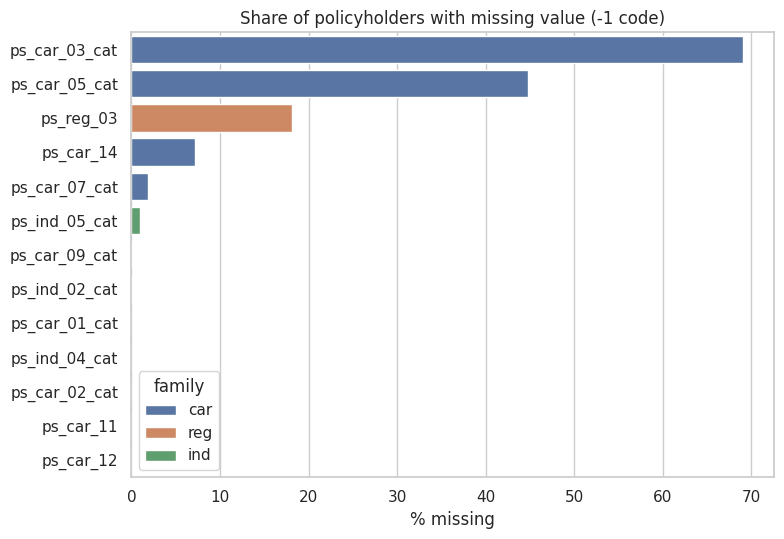

In [ ]:
# Missing values are coded as -1 (NOT NaN). Count them per feature.
miss = count_missing_codes(df_raw).to_frame("n_missing")
miss["pct_missing"] = 100 * miss["n_missing"] / len(df_raw)
miss["family"] = [feature_family(c) for c in miss.index]
display(miss.round(3))

fig, ax = plt.subplots(figsize=(8, 0.35 * len(miss) + 1))
sns.barplot(x="pct_missing", y=miss.index, hue="family", data=miss.reset_index(), dodge=False, ax=ax)
ax.set(title="Share of policyholders with missing value (-1 code)", xlabel="% missing", ylabel="")
plt.tight_layout(); save_fig("01_missing_values"); plt.show()
audit["features_with_missing_codes"] = len(miss)

In [ ]:
# Cardinality of categorical features and outlier audit (IQR rule) for continuous features
card = pd.DataFrame({"n_levels": [df_raw[c].nunique() for c in groups["cat"]]}, index=groups["cat"])
display(card.T)

cont = [c for c in groups["num"] if df_raw[c].nunique() > 20 and not c.startswith("ps_calc_")]
rows = []
for c in cont:
    s = df_raw.loc[df_raw[c] != MISSING_CODE, c]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": c, "q1": q1, "q3": q3, "lower_fence": lo, "upper_fence": hi,
                 "pct_outliers": 100 * ((s < lo) | (s > hi)).mean(), "min": s.min(), "max": s.max()})
outliers = pd.DataFrame(rows).set_index("feature")
display(outliers.round(3))

,ps_ind_02_cat,ps_ind_04_cat,ps_ind_05_cat,ps_car_01_cat,ps_car_02_cat,ps_car_03_cat,ps_car_04_cat,ps_car_05_cat,ps_car_06_cat,ps_car_07_cat,ps_car_08_cat,ps_car_09_cat,ps_car_10_cat,ps_car_11_cat
n_levels,5,3,8,13,3,3,10,3,18,3,2,6,3,104


,q1,q3,lower_fence,upper_fence,pct_outliers,min,max
feature,,,,,,,
ps_reg_03,0.6330,1.0840,-0.0420,1.7600,2.1670,0.0610,4.0380
ps_car_12,0.3160,0.4000,0.1910,0.5260,2.5800,0.1000,1.2650
ps_car_13,0.6710,0.9060,0.3180,1.2590,4.5220,0.2510,3.7210
ps_car_14,0.3500,0.3980,0.2790,0.4700,3.3970,0.1100,0.6360


### Cleaning rules (justified)
| # | Finding | Decision | Why |
|---|---|---|---|
| R1 | Missing values are coded `-1` in 13 features (up to ~69 % for `ps_car_03_cat`) | Replace `-1` with `NaN`; columns holding NaN become `float32` | `-1` would be read as a real (smaller-than-everything) category by linear models and distort means; gradient-boosting libraries handle `NaN` natively and learn the best split direction. Missingness itself is informative → engineered `n_missing` feature in Part 2 |
| R2 | Duplicate rows (ignoring `id`), if any | **Keep** | Features are anonymised/coarse, so identical profiles are expected; they are not errors. Cross-split duplicate overlap is checked in Part 2 |
| R3 | IQR outliers in continuous features | **Keep** | Values are anonymised, no evidence of data errors; tree models are insensitive to monotone outlier effects |
| R4 | No row has missing target, ids unique | No rows dropped | — |
| R5 | 64-bit dtypes | Downcast to int8/int16/int32/float32 | −80 % memory, verified lossless above |

## 1.4 Cleaning, feature dictionary and processed data
We apply R1/R5, build a **feature dictionary** (family, kind, missingness, cardinality, out-of-fold univariate Gini, χ² p-value) and save everything to Parquet. The dictionary is also loaded into SQLite (§1.5).

In [ ]:
df_clean, miss_report = replace_missing_codes(df_raw)
df_clean = optimize_dtypes(df_clean)
assert count_missing_codes(df_clean).empty, "some -1 codes survived cleaning"
print(f"Replaced -1 by NaN in {len(miss_report)} features | memory {mem_mb(df_raw):.0f} MB -> {mem_mb(df_clean):.0f} MB "
      "(columns with NaN are float32)")

t0 = time.perf_counter()
feature_dict = build_feature_dictionary(df_clean)
print(f"Feature dictionary built in {time.perf_counter() - t0:.0f}s")

df_clean.to_parquet(PROCESSED / "train_clean.parquet", index=False)
feature_dict.to_parquet(PROCESSED / "feature_dictionary.parquet", index=False)
audit["features_with_missing_codes"] = len(miss_report)
(REPORTS / "data_audit.json").write_text(json.dumps(audit, indent=2, default=str))

display(feature_dict.sort_values("univariate_gini", ascending=False).head(10))
display(feature_dict.groupby("family")["univariate_gini"].agg(["count", "mean", "max"]).round(4))

Replaced -1 by NaN in 13 features | memory 52 MB -> 69 MB (columns with NaN are float32)
Feature dictionary built in 40s


,feature,family,kind,n_missing,pct_missing,n_unique,univariate_gini,chi2_pvalue
34,ps_car_13,car,num,0,0.0000,70416,0.1482,0.0000
31,ps_car_11_cat,car,cat,0,0.0000,104,0.1211,0.0000
33,ps_car_12,car,num,1,0.0000,183,0.1165,0.0000
19,ps_reg_02,reg,num,0,0.0000,19,0.1094,0.0000
20,ps_reg_03,reg,num,107772,18.1060,5012,0.1089,0.0000
35,ps_car_14,car,num,42620,7.1600,849,0.1037,0.0000
21,ps_car_01_cat,car,cat,107,0.0180,12,0.0998,0.0000
36,ps_car_15,car,num,0,0.0000,15,0.0917,0.0000
2,ps_ind_03,ind,num,0,0.0000,12,0.0849,0.0000
5,ps_ind_06_bin,ind,bin,0,0.0000,2,0.0835,0.0000


,count,mean,max
family,,,
calc,20,-0.0040,0.0056
car,16,0.0732,0.1482
ind,18,0.0316,0.0849
reg,3,0.0970,0.1094


## 1.5 Relational database: normalised schema, ER diagram and SQL analytics
*Requirement 10.* The 57 anonymised features come in four natural **families** (`ind`, `reg`, `car`, `calc`). We normalise the wide table into one table per family (1 : 1 with `policyholder`), plus a `feature_family` lookup and a `feature_dictionary` (many features → one family). Missing values are stored as `NULL`.

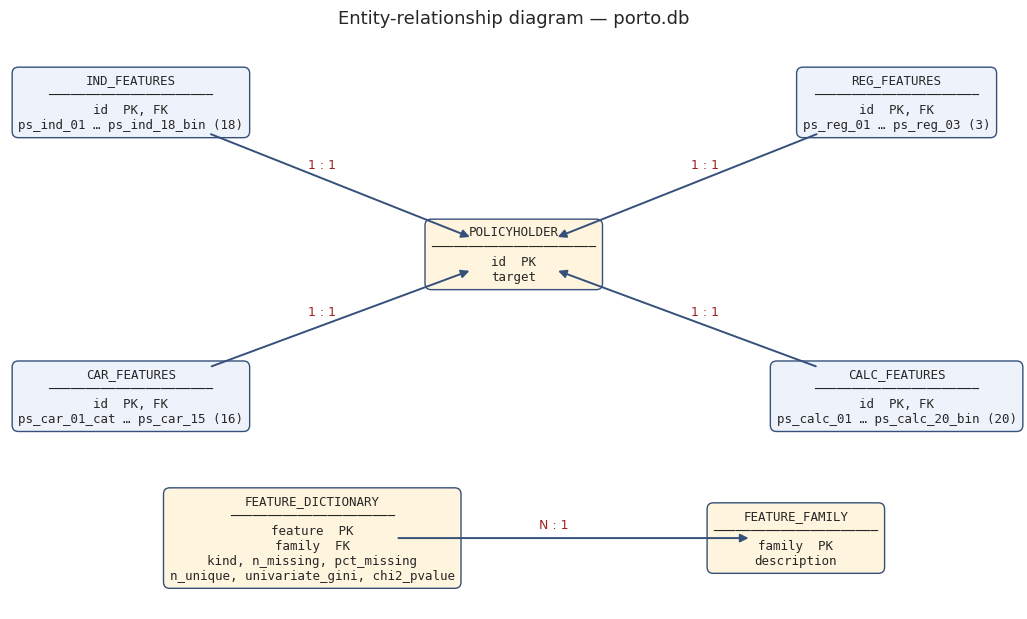

In [ ]:
import matplotlib.patches as mpatches

def draw_er_diagram(path):
    """Draw the ER diagram with matplotlib (no Graphviz dependency)."""
    tables = {
        "policyholder": (0.50, 0.58, ["id  PK", "target"]),
        "ind_features": (0.12, 0.88, ["id  PK, FK", "ps_ind_01 … ps_ind_18_bin (18)"]),
        "reg_features": (0.88, 0.88, ["id  PK, FK", "ps_reg_01 … ps_reg_03 (3)"]),
        "car_features": (0.12, 0.30, ["id  PK, FK", "ps_car_01_cat … ps_car_15 (16)"]),
        "calc_features": (0.88, 0.30, ["id  PK, FK", "ps_calc_01 … ps_calc_20_bin (20)"]),
        "feature_dictionary": (0.30, 0.02, ["feature  PK", "family  FK", "kind, n_missing, pct_missing",
                                           "n_unique, univariate_gini, chi2_pvalue"]),
        "feature_family": (0.78, 0.02, ["family  PK", "description"]),
    }
    fig, ax = plt.subplots(figsize=(13, 7.5)); ax.set_xlim(0, 1); ax.set_ylim(-0.12, 1.02); ax.axis("off")
    boxes = {}
    for name, (x, y, cols) in tables.items():
        text = name.upper() + "\n" + "─" * 22 + "\n" + "\n".join(cols)
        t = ax.text(x, y, text, ha="center", va="center", fontsize=9, family="monospace",
                    bbox=dict(boxstyle="round,pad=0.5", fc="#eef3fb" if "features" in name else "#fff4dd", ec="#35507a"))
        boxes[name] = (x, y)
    def link(a, b, label):
        (x1, y1), (x2, y2) = boxes[a], boxes[b]
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="-|>", color="#35507a", lw=1.4, shrinkA=62, shrinkB=34))
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.02, label, ha="center", fontsize=9, color="#a02020")
    for t in ["ind_features", "reg_features", "car_features", "calc_features"]:
        link(t, "policyholder", "1 : 1")
    link("feature_dictionary", "feature_family", "N : 1")
    ax.set_title("Entity-relationship diagram — porto.db", fontsize=13)
    plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()

draw_er_diagram(FIGURES / "er_diagram.png")

In [ ]:
t0 = time.perf_counter()
conn = load_database(df_clean, feature_dict, DB_PATH)
print(f"Database written in {time.perf_counter() - t0:.0f}s -> {DB_PATH} ({DB_PATH.stat().st_size / 1024**2:.0f} MB)")

# integrity checks
print("PRAGMA integrity_check:", conn.execute("PRAGMA integrity_check").fetchone()[0])
print("Foreign-key violations:", len(conn.execute("PRAGMA foreign_key_check").fetchall()))
counts = pd.read_sql_query("""
    SELECT 'policyholder' AS tbl, COUNT(*) AS n FROM policyholder UNION ALL
    SELECT 'ind_features', COUNT(*) FROM ind_features UNION ALL
    SELECT 'reg_features', COUNT(*) FROM reg_features UNION ALL
    SELECT 'car_features', COUNT(*) FROM car_features UNION ALL
    SELECT 'calc_features', COUNT(*) FROM calc_features UNION ALL
    SELECT 'feature_dictionary', COUNT(*) FROM feature_dictionary UNION ALL
    SELECT 'feature_family', COUNT(*) FROM feature_family""", conn)
display(counts)

Database written in 10s -> /content/data/processed/porto.db (112 MB)
PRAGMA integrity_check: ok
Foreign-key violations: 0


,tbl,n
0,policyholder,595212
1,ind_features,595212
2,reg_features,595212
3,car_features,595212
4,calc_features,595212
5,feature_dictionary,57
6,feature_family,4


### Ten analytical queries (JOIN · GROUP BY/HAVING · subqueries · CTEs · window functions)
Results are loaded into Pandas, saved to `reports/sql/` and re-used later (the decile gain from **Q8** is compared with the final model in Part 3; the missingness effect in **Q4** motivates the `n_missing` feature).

In [ ]:
sql_results = {}
for name, (features_used, sql) in QUERIES.items():
    t0 = time.perf_counter()
    res = run_query(conn, name)
    dt = time.perf_counter() - t0
    sql_results[name] = res
    res.to_csv(REPORTS / "sql" / f"{name.split()[0].lower()}.csv", index=False)
    print(f"\n### {name}   [{features_used}]   ({dt:.1f}s, {len(res)} rows)")
    display(res.head(12))


### Q1 portfolio summary   [aggregate]   (0.1s, 1 rows)


,policyholders,claims,claim_rate_pct
0,595212,21694,3.6450



### Q2 claim rate by vehicle category (JOIN + HAVING)   [join, group by, having]   (0.5s, 12 rows)


,car_01_cat,n,claims,claim_rate_pct
0,9,20323,1106,5.4400
1,1,1367,64,4.6800
2,0,5904,259,4.3900
3,8,15093,655,4.3400
4,2,2144,92,4.2900
5,11,207573,8631,4.1600
6,5,18142,712,3.9200
7,4,26174,1025,3.9200
8,3,6658,250,3.7500
9,10,50087,1852,3.7000



### Q3 driver x vehicle segments (3-table JOIN)   [3-table join, having]   (0.6s, 4 rows)


,ind_17,car_02_cat,n,claim_rate_pct
0,1,0,16361,7.1000
1,1,1,55708,5.0500
2,0,0,84856,4.5400
3,0,1,438282,3.1600


... (10 outputs left out)


### Q9 high-risk segments vs portfolio (HAVING + subquery)   [3-table join, subquery in having]   (0.8s, 7 rows)


,car_01_cat,ind_04_cat,n,claim_rate_pct
0,9,0,11448,5.5900
1,9,1,8875,5.2500
2,8,0,7602,4.5400
3,0,0,2773,4.4400
4,3,1,2590,4.4000
5,11,1,91614,4.3600
6,0,1,3131,4.3400



### Q10 signal by feature family (dictionary JOIN)   [join on dictionary]   (0.0s, 4 rows)


,family,description,n_features,features_with_missing,mean_abs_univariate_gini,max_abs_univariate_gini
0,reg,Regional / area attributes,3,1,0.0970,0.1094
1,car,Vehicle attributes,16,9,0.0744,0.1482
2,ind,Individual (driver) attributes,18,3,0.0355,0.0849
3,calc,Calculated insurer features (anonymised),20,0,0.0059,0.0102


**Reading the results.** The portfolio claim rate is ≈3.6 %. Q2/Q3/Q9 show that vehicle category and driver/vehicle combinations separate low- from high-risk segments; Q4 shows that rows with missing `ps_car_03_cat` / `ps_reg_03` have a *different* claim rate, so missingness carries signal; Q6/Q8 show that a single feature (`ps_car_13`) already concentrates claims in its top deciles (lift > 1) — a useful yardstick for the multivariate model; Q10 shows the `calc` family carries essentially no univariate signal.

                  engine  seconds
          Pandas groupby   0.0230
SQLite (JOIN + GROUP BY)   0.5450
Results identical: True


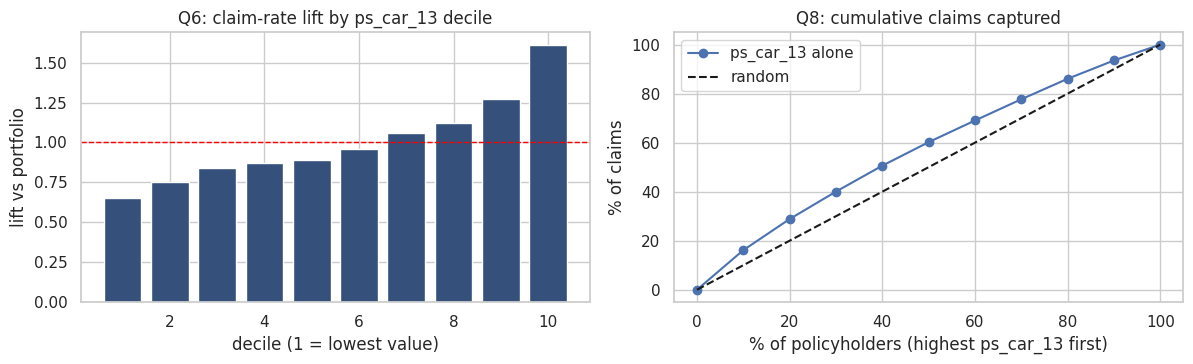

In [ ]:
# Requirement 9 — Pandas vs SQL on the same task (Q2): time and agreement
q2 = "Q2 claim rate by vehicle category (JOIN + HAVING)"
t0 = time.perf_counter(); sql_q2 = run_query(conn, q2); t_sql = time.perf_counter() - t0

t0 = time.perf_counter()
pd_q2 = (df_clean.groupby("ps_car_01_cat", dropna=False)[TARGET]
         .agg(n="size", claims="sum", rate="mean").query("n >= 1000")
         .assign(claim_rate_pct=lambda d: (100 * d["rate"]).round(2)).sort_values("claim_rate_pct", ascending=False))
t_pd = time.perf_counter() - t0

same = np.allclose(np.sort(sql_q2["claims"].to_numpy()), np.sort(pd_q2["claims"].to_numpy()))
print(pd.DataFrame({"engine": ["Pandas groupby", "SQLite (JOIN + GROUP BY)"], "seconds": [t_pd, t_sql]}).round(3).to_string(index=False))
print("Results identical:", same)

# Visual summary of two SQL results
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
q6 = sql_results["Q6 ps_car_13 deciles and lift (NTILE + scalar subquery)"]
axes[0].bar(q6["decile"], q6["lift"], color="#35507a"); axes[0].axhline(1, color="red", ls="--", lw=1)
axes[0].set(title="Q6: claim-rate lift by ps_car_13 decile", xlabel="decile (1 = lowest value)", ylabel="lift vs portfolio")
q8 = sql_results["Q8 cumulative gain of ps_car_13 (running SUM window)"]
axes[1].plot([0] + list(q8["decile"] * 10), [0] + list(q8["cum_claims_captured_pct"]), marker="o", label="ps_car_13 alone")
axes[1].plot([0, 100], [0, 100], "k--", label="random")
axes[1].set(title="Q8: cumulative claims captured", xlabel="% of policyholders (highest ps_car_13 first)", ylabel="% of claims"); axes[1].legend()
plt.tight_layout(); save_fig("02_sql_lift_gain"); plt.show()
conn.close()

## 1.6 Exploratory data analysis and hypothesis tests

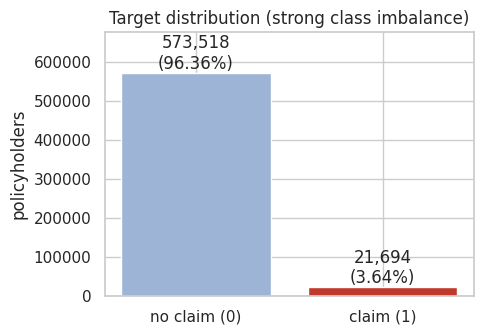

Consequence: accuracy is useless (always predicting 'no claim' gives ~96.4%). We use Gini/ROC-AUC and PR-AUC, and stratified splits.


In [ ]:
# Target balance
vc = df_clean[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["no claim (0)", "claim (1)"], vc.values, color=["#9db4d6", "#c0392b"])
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v:,}\n({100 * v / vc.sum():.2f}%)", ha="center", va="bottom")
ax.set(title="Target distribution (strong class imbalance)", ylabel="policyholders"); ax.set_ylim(0, vc.max() * 1.18)
plt.tight_layout(); save_fig("03_target_balance"); plt.show()
print("Consequence: accuracy is useless (always predicting 'no claim' gives ~96.4%). We use Gini/ROC-AUC and PR-AUC, and stratified splits.")

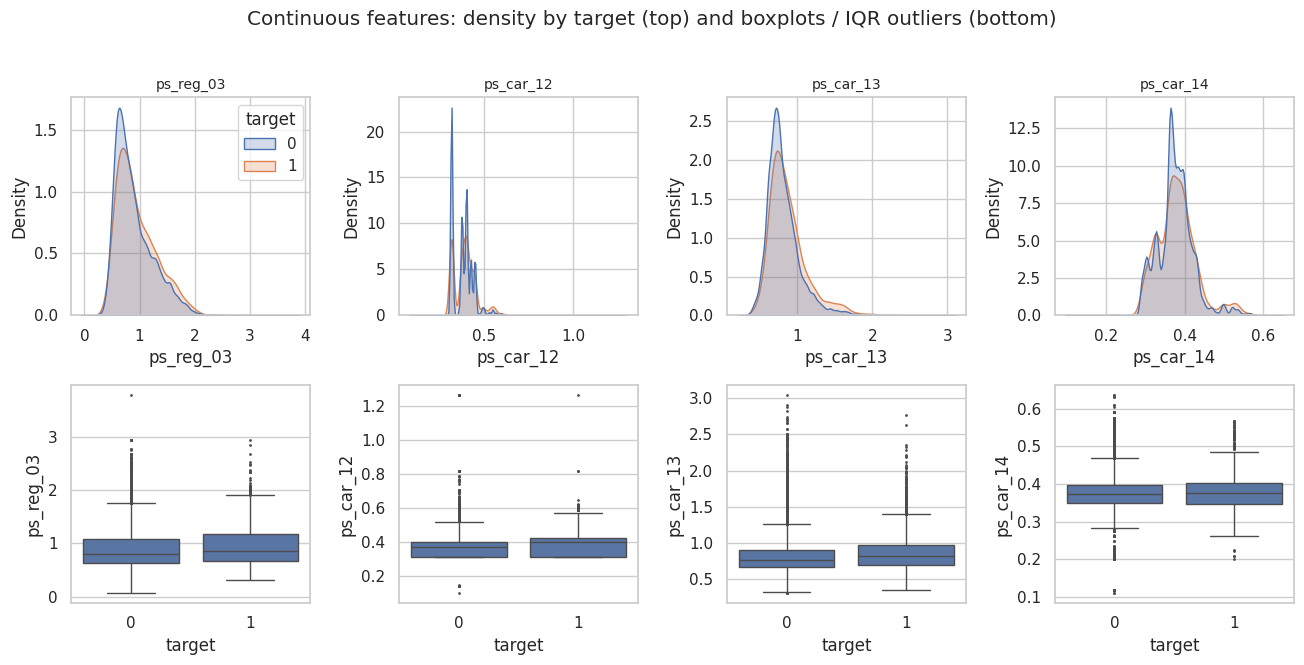

In [ ]:
# Distributions of continuous features by target + outlier boxplots
cont = [c for c in feature_dict.query("kind == 'num' and n_unique > 20 and family != 'calc'")["feature"]]
sample = df_clean.sample(min(100_000, len(df_clean)), random_state=SEED)
fig, axes = plt.subplots(2, len(cont), figsize=(3.3 * len(cont), 6.5))
for j, c in enumerate(cont):
    sns.kdeplot(data=sample, x=c, hue=TARGET, common_norm=False, fill=True, ax=axes[0, j], legend=(j == 0), warn_singular=False)
    axes[0, j].set_title(c, fontsize=10)
    sns.boxplot(data=sample, x=TARGET, y=c, ax=axes[1, j], fliersize=1)
plt.suptitle("Continuous features: density by target (top) and boxplots / IQR outliers (bottom)", y=1.02)
plt.tight_layout(); save_fig("04_continuous_distributions"); plt.show()

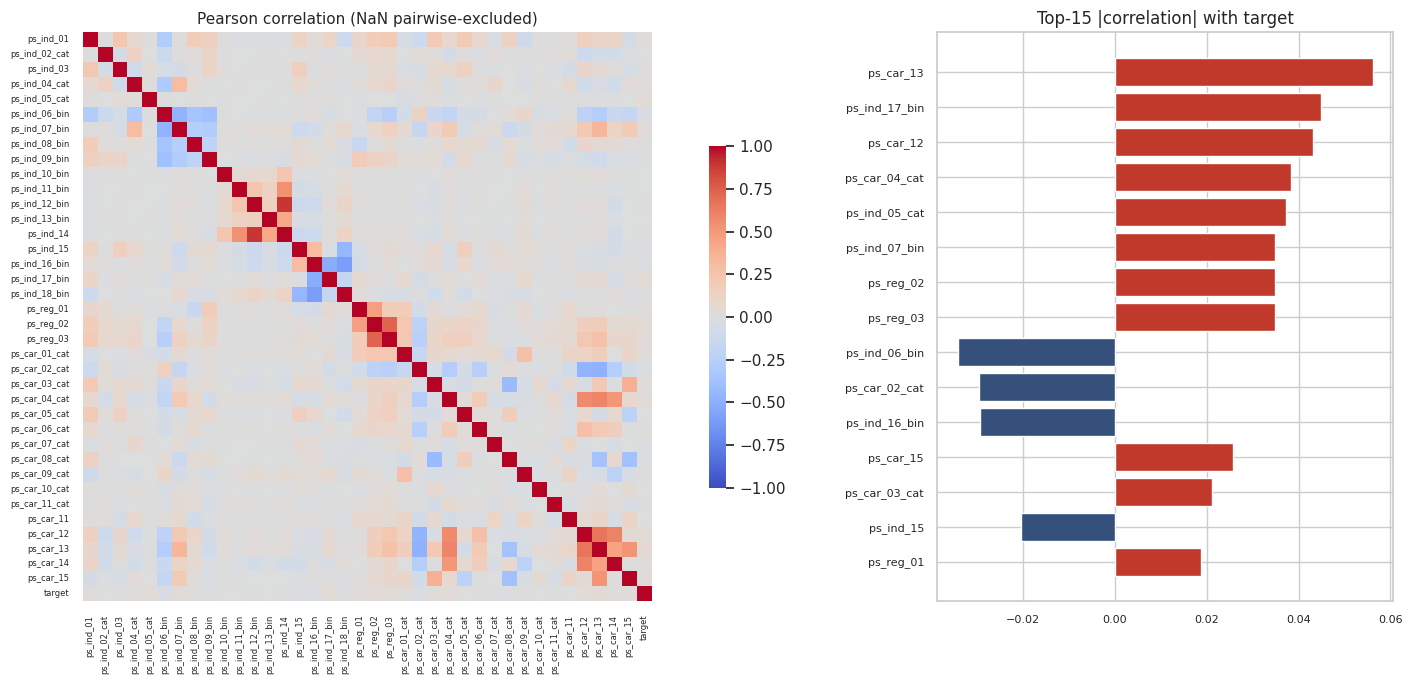

Highly correlated feature pairs (|r| > 0.6) -> multicollinearity matters for linear models, not for trees:


,level_0,level_1,r
353,ps_ind_12_bin,ps_ind_14,0.8934
532,ps_reg_02,ps_reg_03,0.7397
693,ps_car_12,ps_car_13,0.6711
694,ps_car_12,ps_car_14,0.6058


In [ ]:
# Correlation analysis (calc features excluded from the heatmap for readability; they are ~uncorrelated)
feat_no_calc = [c for c in features if not c.startswith("ps_calc_")]
corr = sample[feat_no_calc + [TARGET]].corr()
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [3, 1.2]})
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.6},
            xticklabels=True, yticklabels=True, ax=axes[0])
axes[0].set_title("Pearson correlation (NaN pairwise-excluded)", fontsize=11)
axes[0].tick_params(labelsize=6)
tgt = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(15)[::-1]
axes[1].barh(tgt.index, tgt.values, color=np.where(tgt.values > 0, "#c0392b", "#35507a"))
axes[1].set(title="Top-15 |correlation| with target"); axes[1].tick_params(labelsize=8)
plt.tight_layout(); save_fig("05_correlation"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("r").reset_index()
         .query("abs(r) > 0.6 and level_0 != @TARGET and level_1 != @TARGET").sort_values("r", key=abs, ascending=False))
print("Highly correlated feature pairs (|r| > 0.6) -> multicollinearity matters for linear models, not for trees:")
display(pairs.head(12))

,n_features,significant,mean_abs_gini
family,,,
calc,20,0,0.0059
car,16,15,0.0744
ind,18,15,0.0355
reg,3,3,0.0970


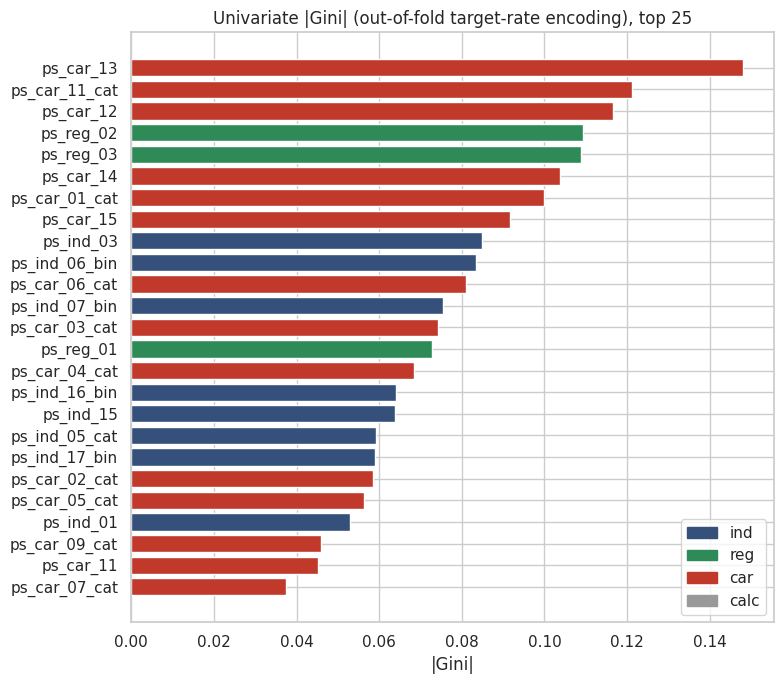

H0: feature independent of target (chi-square on value/quantile groups, BH-corrected at 5% FDR).
Hypothesis 1 (calc features carry no signal) -> tested in Part 2 with a CV ablation of the LightGBM model.


In [ ]:
# Univariate signal per feature family + multiple-testing-corrected hypothesis tests
def bh_significant(pvals, alpha=0.05):
    """Benjamini-Hochberg FDR control."""
    p = np.asarray(pvals); m = len(p); order = np.argsort(p)
    passed = p[order] <= alpha * np.arange(1, m + 1) / m
    k = np.max(np.where(passed)[0]) + 1 if passed.any() else 0
    sig = np.zeros(m, dtype=bool); sig[order[:k]] = True
    return sig

fd = feature_dict.copy()
fd["significant_fdr5"] = bh_significant(fd["chi2_pvalue"])
display(fd.groupby("family").agg(n_features=("feature", "count"), significant=("significant_fdr5", "sum"),
                                 mean_abs_gini=("univariate_gini", lambda s: s.abs().mean())).round(4))

top = fd.assign(abs_gini=fd["univariate_gini"].abs()).sort_values("abs_gini", ascending=False).head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
palette = {"ind": "#35507a", "reg": "#2e8b57", "car": "#c0392b", "calc": "#999999"}
ax.barh(top["feature"], top["abs_gini"], color=[palette.get(f, "#000") for f in top["family"]])
ax.set(title="Univariate |Gini| (out-of-fold target-rate encoding), top 25", xlabel="|Gini|")
ax.legend(handles=[mpatches.Patch(color=v, label=k) for k, v in palette.items()], loc="lower right")
plt.tight_layout(); save_fig("06_univariate_gini"); plt.show()
print("H0: feature independent of target (chi-square on value/quantile groups, BH-corrected at 5% FDR).")
print("Hypothesis 1 (calc features carry no signal) -> tested in Part 2 with a CV ablation of the LightGBM model.")

In [ ]:
# Interactive Plotly explorer: claim rate by level, choose the feature in the dropdown
import plotly.graph_objects as go

base_rate = 100 * df_clean[TARGET].mean()
explorer = [c for c in feature_dict.query("n_unique <= 30 and family != 'calc'")["feature"]]
fig = go.Figure()
for i, c in enumerate(explorer):
    g = df_clean.groupby(c, dropna=False)[TARGET].agg(["size", "mean"]).reset_index()
    g["level"] = g[c].map(lambda v: "missing" if pd.isna(v) else (str(int(v)) if float(v).is_integer() else f"{v:.3g}"))
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    fig.add_trace(go.Bar(x=g["level"], y=100 * g["mean"], error_y=dict(type="data", array=196 * se), name=c,
                         visible=(i == 0), customdata=g["size"], marker_color="#35507a",
                         hovertemplate="level %{x}<br>claim rate %{y:.2f}%<br>n = %{customdata:,}<extra></extra>"))
buttons = [dict(label=c, method="update",
                args=[{"visible": [j == i for j in range(len(explorer))]}, {"title": f"Claim rate by {c} (95% CI)"}])
           for i, c in enumerate(explorer)]
fig.update_layout(title=f"Claim rate by {explorer[0]} (95% CI)", yaxis_title="claim rate, %", xaxis_title="level",
                  updatemenus=[dict(buttons=buttons, direction="down", x=0.0, y=1.18, xanchor="left")],
                  shapes=[dict(type="line", xref="paper", x0=0, x1=1, y0=base_rate, y1=base_rate,
                               line=dict(color="red", dash="dash"))],
                  annotations=[dict(xref="paper", x=1, y=base_rate, text=f"portfolio {base_rate:.2f}%", showarrow=False,
                                    yanchor="bottom", xanchor="right", font=dict(color="red"))],
                  template="plotly_white", height=480)
fig.write_html(REPORTS / "claim_rate_explorer.html")
fig.show()
print("Saved standalone copy: reports/claim_rate_explorer.html (GitHub does not render Plotly output inside notebooks)")

Saved standalone copy: reports/claim_rate_explorer.html (GitHub does not render Plotly output inside notebooks)


### Part 1 — takeaways
* **Scale / memory:** 595K rows × 59 columns; dtype downcasting cuts RAM by roughly 80 % without changing a single value; Parquet reads far faster and is much smaller than CSV.
* **Quality:** ids unique, no constant columns, missingness only through the `-1` code (13 features, 4 of them above 5 %: `ps_car_03_cat`, `ps_car_05_cat`, `ps_reg_03`, `ps_car_14`). `-1` → `NaN` is the one cleaning step needed.
* **Signal:** weak and concentrated — a handful of `car`, `reg` and `ind` features carry nearly all univariate signal; `calc` features look like noise (checked statistically here, and by ablation in Part 2).
* **Imbalance:** ~3.6 % positives → rank metrics (Gini/ROC-AUC) and PR-AUC; stratified splits.
* **SQL layer:** normalised schema with 10 analytical queries; its decile-gain output is a baseline for the model in Part 3.

# PART 2 — Modelling and model comparison
**Protocol (no leakage).** (1) one stratified 80/20 split *before* anything is fitted; (2) all model/feature/hyper-parameter **selection uses cross-validation inside the 80 % training part only**; (3) the 20 % hold-out is scored once per model for reporting. Row-wise engineered features are stateless, so they cannot leak across the split; every fitted transformer (imputers, scalers, encoders) lives inside a scikit-learn `Pipeline`/`ColumnTransformer` and is fitted on training folds only.

*Why a stratified random split and not a temporal/group split?* The data has no date and no policyholder/group key (ids are shuffled and each row is one policyholder), so there is nothing to split by; stratification keeps the 3.6 % positive rate identical in all folds. We additionally check for identical feature rows appearing on both sides of the split (§2.0).

In [ ]:
import sys, os, json, time, gc, warnings, sqlite3
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.model_selection import train_test_split
import lightgbm as lgb
import xgboost as xgb
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
from src.config import (SEED, PROCESSED, MODELS, REPORTS, FIGURES, DB_PATH, TEST_SIZE, CV_FOLDS,
                        N_TRIALS_LGBM, N_TRIALS_XGB, save_fig)
from src.data_utils import (ID_COL, TARGET, ENGINEERED, add_features, select_feature_set, classify_columns)
from src.metrics import evaluate_predictions, bootstrap_auc_ci, paired_bootstrap_diff
from src.modeling import (make_pipeline, fit_timed, predict_timed, model_size_mb, make_cv_splits,
                          lgbm_cv, xgb_cv, run_study)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 150, "display.float_format", "{:.4f}".format)
np.random.seed(SEED)

## 2.0 Load processed data and split

In [ ]:
df = pd.read_parquet(PROCESSED / "train_clean.parquet")
df = add_features(df)               # +4 engineered columns (row-wise, stateless): n_missing, ind_bin_sum, car13_x_reg03, reg_sum
raw_cols = [c for c in df.columns if c not in (ID_COL, TARGET) and c not in ENGINEERED]
print(f"{df.shape[0]:,} rows, {len(raw_cols)} raw features + {len(ENGINEERED)} engineered")

idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=df[TARGET], random_state=SEED)
train_df, test_df = df.iloc[idx_train].reset_index(drop=True), df.iloc[idx_test].reset_index(drop=True)
y_train, y_test = train_df[TARGET], test_df[TARGET]
pd.DataFrame({ID_COL: df[ID_COL].iloc[idx_test]}).to_parquet(PROCESSED / "holdout_ids.parquet", index=False)

print(f"train {len(train_df):,} (claim rate {100 * y_train.mean():.3f}%) | test {len(test_df):,} (claim rate {100 * y_test.mean():.3f}%)")

# leakage checks: id overlap and identical feature rows on both sides of the split
assert set(train_df[ID_COL]).isdisjoint(set(test_df[ID_COL])), "id overlap!"
h_tr = set(pd.util.hash_pandas_object(train_df[raw_cols], index=False))
h_te = pd.util.hash_pandas_object(test_df[raw_cols], index=False)
dup_share = 100 * h_te.isin(h_tr).mean()
print(f"Hold-out rows whose exact feature vector also occurs in train: {dup_share:.2f}%")

cv_splits = make_cv_splits(train_df, y_train, CV_FOLDS, SEED)   # identical folds are re-used by every CV below

595,212 rows, 57 raw features + 4 engineered
train 476,169 (claim rate 3.645%) | test 119,043 (claim rate 3.645%)
Hold-out rows whose exact feature vector also occurs in train: 0.00%


## 2.1 Feature-set ablation (Hypothesis 1: the `ps_calc_*` features are noise)
Three feature sets are compared with the same LightGBM settings by stratified CV **on the training part only**:
`raw_all` (57) · `drop_calc` (no `ps_calc_*`) · `drop_calc+engineered` (+ `n_missing`, `ind_bin_sum`, `car13_x_reg03`, `reg_sum`). The winner by mean CV-AUC becomes the feature set for all later models.

In [ ]:
ablation_params = dict(learning_rate=0.1, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
                       colsample_bytree=0.7, reg_lambda=1.0)
rows = []
for name in ["raw_all", "drop_calc", "drop_calc+engineered"]:
    cols = select_feature_set(train_df, name)
    t0 = time.perf_counter()
    mean, std, rounds = lgbm_cv(ablation_params, train_df[cols], y_train, cv_splits, seed=SEED)
    rows.append({"feature_set": name, "n_features": len(cols), "cv_auc": mean, "cv_auc_std": std,
                 "cv_gini": 2 * mean - 1, "best_rounds": rounds, "seconds": time.perf_counter() - t0})
ablation = pd.DataFrame(rows).set_index("feature_set")
display(ablation)

best_fs = ablation["cv_auc"].idxmax()
FEATURES = select_feature_set(train_df, best_fs)
print(f"Selected feature set: {best_fs} ({len(FEATURES)} features)")
gain_vs_raw = ablation.loc[best_fs, "cv_auc"] - ablation.loc["raw_all", "cv_auc"]
print(f"CV-AUC gain vs using all raw features: {gain_vs_raw:+.5f} (fold std ≈ {ablation.loc[best_fs, 'cv_auc_std']:.5f}; "
      "differences below ~1 std are within noise)")
ablation.to_csv(REPORTS / "feature_set_ablation.csv")
X_train, X_test = train_df[FEATURES], test_df[FEATURES]

,n_features,cv_auc,cv_auc_std,cv_gini,best_rounds,seconds
feature_set,,,,,,
raw_all,57,0.6349,0.0039,0.2698,51,34.6982
drop_calc,37,0.6369,0.0028,0.2738,76,30.1180
drop_calc+engineered,41,0.6363,0.0034,0.2727,71,30.3859


Selected feature set: drop_calc (37 features)
CV-AUC gain vs using all raw features: +0.00198 (fold std ≈ 0.00280; differences below ~1 std are within noise)


## 2.2 Baselines and default-parameter models
Six model families, all wrapped in a `Pipeline(preprocessor → model)`:

| Model | Role | Preprocessor |
|---|---|---|
| `DummyClassifier(prior)` | trivial baseline (AUC = 0.5) | impute |
| Logistic regression | linear baseline | median-impute + scale, one-hot for `_cat` |
| Random Forest | bagging baseline | constant-impute |
| HistGradientBoosting | scikit-learn boosting | native NaN |
| **LightGBM (default-ish)** | boosting baseline for the tuning comparison | native NaN |
| XGBoost (default-ish) | second boosting library | native NaN |

For each model we record fit time, inference time per 1000 rows and serialised size in addition to the quality metrics (requirement 9). The hold-out is used here for **reporting only**.

In [ ]:
results, PREDS, FITTED = [], {}, {}

def run_model(name, pipe, stage):
    pipe, t_fit = fit_timed(pipe, X_train, y_train)
    proba, ms1000 = predict_timed(pipe, X_test)
    results.append({"model": name, "stage": stage, **evaluate_predictions(y_test, proba),
                    "fit_s": t_fit, "infer_ms_per_1000": ms1000, "size_mb": model_size_mb(pipe)})
    PREDS[name], FITTED[name] = proba, pipe
    r = results[-1]
    print(f"{name:<28} AUC {r['roc_auc']:.4f}  Gini {r['gini']:.4f}  PR-AUC {r['pr_auc']:.4f}  fit {t_fit:6.1f}s")

run_model("Dummy (prior)", make_pipeline(DummyClassifier(strategy="prior"), "tree_impute", FEATURES), "baseline")
run_model("Logistic Regression", make_pipeline(LogisticRegression(C=0.1, max_iter=300), "linear", FEATURES), "baseline")
run_model("Random Forest", make_pipeline(RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=200,
          max_features="sqrt", n_jobs=-1, random_state=SEED), "tree_impute", FEATURES), "default")
run_model("HistGradientBoosting", make_pipeline(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
          max_leaf_nodes=31, min_samples_leaf=100, l2_regularization=1.0, early_stopping=False,
          random_state=SEED), "tree_nan", FEATURES), "default")
run_model("LightGBM (default)", make_pipeline(LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
          n_jobs=-1, random_state=SEED, verbosity=-1), "tree_nan", FEATURES), "default")
run_model("XGBoost (default)", make_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
          tree_method="hist", n_jobs=-1, random_state=SEED, eval_metric="auc"), "tree_nan", FEATURES), "default")

Dummy (prior)                AUC 0.5000  Gini 0.0000  PR-AUC 0.0364  fit    0.3s
Logistic Regression          AUC 0.6328  Gini 0.2656  PR-AUC 0.0651  fit    4.8s
Random Forest                AUC 0.6325  Gini 0.2650  PR-AUC 0.0640  fit   82.8s
HistGradientBoosting         AUC 0.6360  Gini 0.2719  PR-AUC 0.0666  fit   31.5s
LightGBM (default)           AUC 0.6380  Gini 0.2760  PR-AUC 0.0663  fit   15.3s
XGBoost (default)            AUC 0.6354  Gini 0.2708  PR-AUC 0.0672  fit   20.4s


## 2.3 Hyper-parameter tuning with cross-validation
Optuna (TPE sampler) maximises the mean **stratified-CV ROC-AUC** on the training part, using native `lgb.cv` / `xgb.cv` with early stopping so the number of trees is tuned jointly with the other parameters. Learning rate is fixed at 0.05. Increase `N_TRIALS_*` in `src/config.py` for a better search (this is the slowest part of the notebook).

In [ ]:
# CV score of the *default* LightGBM settings, for an apples-to-apples comparison with the tuned model
default_lgbm_params = dict(learning_rate=0.05, num_leaves=31)
cv_default = lgbm_cv(default_lgbm_params, X_train, y_train, cv_splits, seed=SEED)
print(f"LightGBM default  CV-AUC {cv_default[0]:.5f} ± {cv_default[1]:.5f}  (rounds {cv_default[2]})")

t0 = time.perf_counter()
lgbm_params, lgbm_rounds, study_lgbm = run_study("lgbm", X_train, y_train, cv_splits, N_TRIALS_LGBM, SEED)
t_tune_lgbm = time.perf_counter() - t0
print(f"LightGBM tuned    CV-AUC {study_lgbm.best_value:.5f} ± {study_lgbm.best_trial.user_attrs['auc_std']:.5f}  "
      f"(rounds {lgbm_rounds}, {N_TRIALS_LGBM} trials, {t_tune_lgbm / 60:.1f} min)")
print(json.dumps({k: round(v, 5) if isinstance(v, float) else v for k, v in lgbm_params.items()}, indent=2))

LightGBM default  CV-AUC 0.63785 ± 0.00305  (rounds 175)
LightGBM tuned    CV-AUC 0.64124 ± 0.00307  (rounds 486, 20 trials, 21.7 min)
{
  "learning_rate": 0.05,
  "subsample_freq": 1,
  "num_leaves": 9,
  "min_child_samples": 126,
  "subsample": 0.8428,
  "colsample_bytree": 0.88354,
  "reg_alpha": 0.04962,
  "reg_lambda": 21.81777
}


XGBoost tuned     CV-AUC 0.64097 ± 0.00295  (rounds 395, 12 trials, 45.6 min)
{
  "learning_rate": 0.05,
  "max_depth": 4,
  "min_child_weight": 15.44478,
  "subsample": 0.9522,
  "colsample_bytree": 0.68279,
  "reg_alpha": 0.0115,
  "reg_lambda": 0.00593,
  "gamma": 0.00433
}


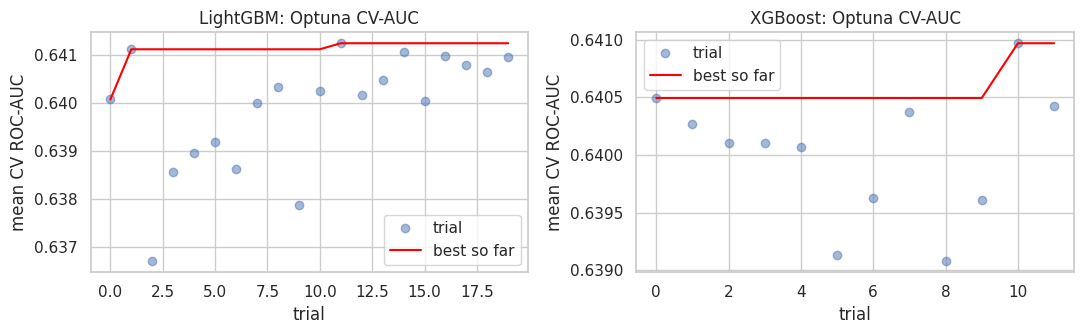

In [ ]:
t0 = time.perf_counter()
xgb_params, xgb_rounds, study_xgb = run_study("xgb", X_train, y_train, cv_splits, N_TRIALS_XGB, SEED)
t_tune_xgb = time.perf_counter() - t0
print(f"XGBoost tuned     CV-AUC {study_xgb.best_value:.5f} ± {study_xgb.best_trial.user_attrs['auc_std']:.5f}  "
      f"(rounds {xgb_rounds}, {N_TRIALS_XGB} trials, {t_tune_xgb / 60:.1f} min)")
print(json.dumps({k: round(v, 5) if isinstance(v, float) else v for k, v in xgb_params.items()}, indent=2))

# optimisation history
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, study, title in [(axes[0], study_lgbm, "LightGBM"), (axes[1], study_xgb, "XGBoost")]:
    vals = study.trials_dataframe()["value"]
    ax.plot(vals, "o", alpha=0.5, label="trial"); ax.plot(vals.cummax(), "-", color="red", label="best so far")
    ax.set(title=f"{title}: Optuna CV-AUC", xlabel="trial", ylabel="mean CV ROC-AUC"); ax.legend()
plt.tight_layout(); save_fig("07_optuna_history"); plt.show()

## 2.4 Final fit and hold-out evaluation
The tuned models are re-fitted on the **full training part** (number of trees × 1.1 because each CV fold saw 2/3 of the data) and scored once on the hold-out. A simple probability average of tuned LightGBM and XGBoost is included as an ensemble extension. The **final model is chosen by CV-AUC** (not by hold-out score).

In [ ]:
n_lgb, n_xgb = int(lgbm_rounds * 1.1), int(xgb_rounds * 1.1)
run_model("LightGBM (tuned)", make_pipeline(LGBMClassifier(**lgbm_params, n_estimators=n_lgb, n_jobs=-1,
          random_state=SEED, verbosity=-1), "tree_nan", FEATURES), "tuned")
run_model("XGBoost (tuned)", make_pipeline(XGBClassifier(**xgb_params, n_estimators=n_xgb, tree_method="hist",
          n_jobs=-1, random_state=SEED, eval_metric="auc"), "tree_nan", FEATURES), "tuned")

# ensemble: average of the two tuned boosters
blend = 0.5 * PREDS["LightGBM (tuned)"] + 0.5 * PREDS["XGBoost (tuned)"]
PREDS["Blend (LGBM+XGB tuned)"] = blend
tl = [r for r in results if r["model"] == "LightGBM (tuned)"][0]; tx = [r for r in results if r["model"] == "XGBoost (tuned)"][0]
results.append({"model": "Blend (LGBM+XGB tuned)", "stage": "ensemble", **evaluate_predictions(y_test, blend),
                "fit_s": tl["fit_s"] + tx["fit_s"], "infer_ms_per_1000": tl["infer_ms_per_1000"] + tx["infer_ms_per_1000"],
                "size_mb": tl["size_mb"] + tx["size_mb"]})

res_df = pd.DataFrame(results).set_index("model")
display(res_df.sort_values("roc_auc", ascending=False))

LightGBM (tuned)             AUC 0.6437  Gini 0.2873  PR-AUC 0.0689  fit   22.7s
XGBoost (tuned)              AUC 0.6410  Gini 0.2821  PR-AUC 0.0681  fit   23.4s


,stage,roc_auc,gini,pr_auc,log_loss,brier,fit_s,infer_ms_per_1000,size_mb
model,,,,,,,,,
LightGBM (tuned),tuned,0.6437,0.2873,0.0689,0.1516,0.0347,22.6906,14.5019,0.5899
Blend (LGBM+XGB tuned),ensemble,0.6429,0.2858,0.0686,0.1517,0.0347,46.1071,20.8252,1.2716
XGBoost (tuned),tuned,0.6410,0.2821,0.0681,0.1518,0.0347,23.4165,6.3233,0.6816
LightGBM (default),default,0.6380,0.2760,0.0663,0.1521,0.0348,15.2854,15.0494,1.0008
HistGradientBoosting,default,0.6360,0.2719,0.0666,0.1522,0.0348,31.4730,20.2223,1.0522
XGBoost (default),default,0.6354,0.2708,0.0672,0.1522,0.0348,20.4493,6.6073,1.2699
Logistic Regression,baseline,0.6328,0.2656,0.0651,0.1523,0.0348,4.8251,2.7470,0.0103
Random Forest,default,0.6325,0.2650,0.0640,0.1525,0.0348,82.7943,8.6071,7.0399
Dummy (prior),baseline,0.5000,0.0000,0.0364,0.1565,0.0351,0.2934,0.4199,0.0044


,auc,ci_low,ci_high,gini_low,gini_high
model,,,,,
Logistic Regression,0.6328,0.6244,0.6414,0.2487,0.2828
Random Forest,0.6325,0.6241,0.6399,0.2482,0.2798
HistGradientBoosting,0.6360,0.6275,0.6446,0.2551,0.2893
LightGBM (default),0.6380,0.6299,0.6461,0.2598,0.2922
XGBoost (default),0.6354,0.6273,0.6432,0.2547,0.2864
LightGBM (tuned),0.6437,0.6351,0.6519,0.2701,0.3038
XGBoost (tuned),0.6410,0.6327,0.6498,0.2654,0.2997
Blend (LGBM+XGB tuned),0.6429,0.6341,0.6513,0.2682,0.3027


Tuned - default LightGBM: ΔAUC = +0.00583  (95% CI +0.00361 … +0.00772); share of resamples with Δ ≤ 0: 0.00


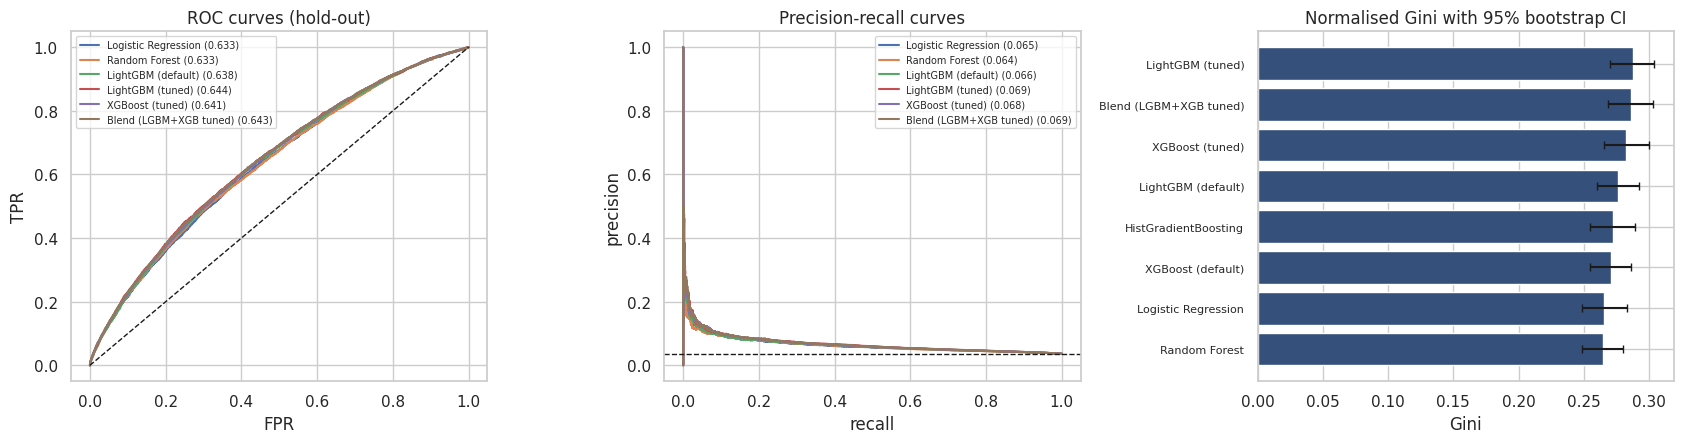

In [ ]:
# Uncertainty: bootstrap CIs of hold-out AUC, and a paired test tuned vs default LightGBM
ci_rows = []
for m in ["Logistic Regression", "Random Forest", "HistGradientBoosting", "LightGBM (default)", "XGBoost (default)",
          "LightGBM (tuned)", "XGBoost (tuned)", "Blend (LGBM+XGB tuned)"]:
    lo, hi = bootstrap_auc_ci(y_test, PREDS[m], n_boot=200, seed=SEED)
    ci_rows.append({"model": m, "auc": res_df.loc[m, "roc_auc"], "ci_low": lo, "ci_high": hi, "gini_low": 2 * lo - 1, "gini_high": 2 * hi - 1})
ci = pd.DataFrame(ci_rows).set_index("model"); display(ci)

d, (dlo, dhi), p_le0 = paired_bootstrap_diff(y_test, PREDS["LightGBM (tuned)"], PREDS["LightGBM (default)"], n_boot=200, seed=SEED)
print(f"Tuned - default LightGBM: ΔAUC = {d:+.5f}  (95% CI {dlo:+.5f} … {dhi:+.5f}); share of resamples with Δ ≤ 0: {p_le0:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
plot_models = ["Logistic Regression", "Random Forest", "LightGBM (default)", "LightGBM (tuned)", "XGBoost (tuned)", "Blend (LGBM+XGB tuned)"]
for m in plot_models:
    fpr, tpr, _ = roc_curve(y_test, PREDS[m]); axes[0].plot(fpr, tpr, label=f"{m} ({res_df.loc[m, 'roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, PREDS[m]); axes[1].plot(rc, pr, label=f"{m} ({res_df.loc[m, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(title="ROC curves (hold-out)", xlabel="FPR", ylabel="TPR"); axes[0].legend(fontsize=7)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set(title="Precision-recall curves", xlabel="recall", ylabel="precision"); axes[1].legend(fontsize=7)
order = res_df.drop("Dummy (prior)").sort_values("gini")
axes[2].barh(order.index, order["gini"], xerr=[(order["gini"] - ci["gini_low"].reindex(order.index)).fillna(0),
             (ci["gini_high"].reindex(order.index) - order["gini"]).fillna(0)], color="#35507a", capsize=3)
axes[2].set(title="Normalised Gini with 95% bootstrap CI", xlabel="Gini"); axes[2].tick_params(axis="y", labelsize=8)
plt.tight_layout(); save_fig("08_model_comparison"); plt.show()

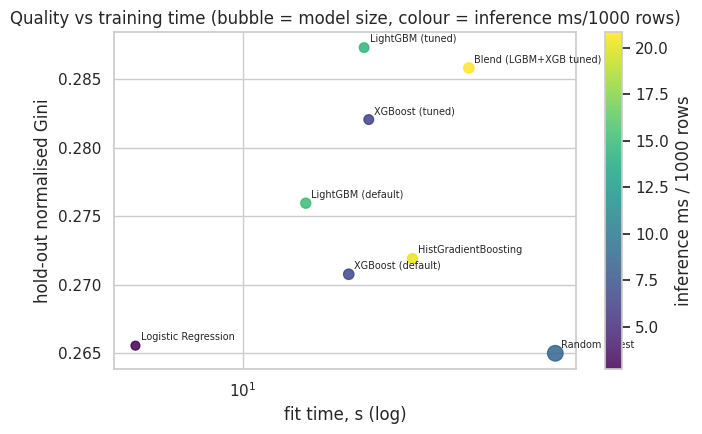

In [ ]:
# Quality vs cost trade-off
fig, ax = plt.subplots(figsize=(7, 4.5))
tmp = res_df.drop("Dummy (prior)")
sc = ax.scatter(tmp["fit_s"], tmp["gini"], s=40 + 12 * tmp["size_mb"], c=tmp["infer_ms_per_1000"], cmap="viridis", alpha=0.85)
for name, r in tmp.iterrows():
    ax.annotate(name, (r["fit_s"], r["gini"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set(xlabel="fit time, s (log)", ylabel="hold-out normalised Gini", title="Quality vs training time (bubble = model size, colour = inference ms/1000 rows)")
plt.colorbar(sc, label="inference ms / 1000 rows"); plt.tight_layout(); save_fig("09_quality_vs_cost"); plt.show()

In [ ]:
# Choose the final model by CROSS-VALIDATION (not by hold-out), then persist everything
cv_scores = {"LightGBM (tuned)": study_lgbm.best_value, "XGBoost (tuned)": study_xgb.best_value}
final_name = max(cv_scores, key=cv_scores.get)
print("Final model (best CV-AUC):", final_name, cv_scores)

# artefacts: models (joblib), metrics (Parquet + SQLite), predictions, parameters
joblib.dump(FITTED["LightGBM (tuned)"], MODELS / "lgbm_tuned.joblib")
joblib.dump(FITTED["XGBoost (tuned)"], MODELS / "xgb_tuned.joblib")
joblib.dump(FITTED[final_name], MODELS / "final_model.joblib")
(MODELS / "final_meta.json").write_text(json.dumps({
    "final_model": final_name, "features": FEATURES, "feature_set": best_fs, "cv_auc": cv_scores,
    "lgbm_params": lgbm_params, "lgbm_n_estimators": n_lgb, "xgb_params": xgb_params, "xgb_n_estimators": n_xgb,
    "seed": SEED, "cv_folds": CV_FOLDS}, indent=2))

res_out = res_df.reset_index()
res_out.to_parquet(REPORTS / "model_comparison.parquet", index=False)
res_out.round(5).to_csv(REPORTS / "model_comparison.csv", index=False)
pd.DataFrame({ID_COL: test_df[ID_COL], TARGET: y_test, **{m: p for m, p in PREDS.items()}}).to_parquet(REPORTS / "test_predictions.parquet", index=False)

params_json = {"LightGBM (tuned)": {**lgbm_params, "n_estimators": n_lgb}, "XGBoost (tuned)": {**xgb_params, "n_estimators": n_xgb}}
exp = res_out.assign(params=res_out["model"].map(lambda m: json.dumps(params_json.get(m, {}))),
                     feature_set=best_fs, run_ts=pd.Timestamp.now().isoformat(timespec="seconds"))
with sqlite3.connect(DB_PATH) as c:
    exp.to_sql("experiments", c, if_exists="replace", index=False)
    print(pd.read_sql_query("SELECT model, stage, ROUND(gini,4) AS gini, ROUND(fit_s,1) AS fit_s FROM experiments ORDER BY gini DESC", c))

Final model (best CV-AUC): LightGBM (tuned) {'LightGBM (tuned)': 0.6412419365446816, 'XGBoost (tuned)': 0.6409680610561749}
                    model     stage   gini   fit_s
0        LightGBM (tuned)     tuned 0.2873 22.7000
1  Blend (LGBM+XGB tuned)  ensemble 0.2858 46.1000
2         XGBoost (tuned)     tuned 0.2821 23.4000
3      LightGBM (default)   default 0.2760 15.3000
4    HistGradientBoosting   default 0.2719 31.5000
5       XGBoost (default)   default 0.2708 20.4000
6     Logistic Regression  baseline 0.2656  4.8000
7           Random Forest   default 0.2650 82.8000
8           Dummy (prior)  baseline 0.0000  0.3000


### Part 2 — takeaways
* The **baseline ladder** (Dummy → logistic regression → Random Forest → boosting) shows how much is gained from non-linear tree boosting on anonymised features; absolute Gini values in this competition are low by nature (the signal is weak), so differences of ±0.002 are often within the bootstrap noise — hence the CIs and the paired test above.
* The **ablation** tests whether dropping `ps_calc_*` and adding the engineered features changes CV-AUC beyond fold noise.
* Tuning is judged by CV on the training part, and the hold-out is touched once per model.
* The **blend** and **final model** selection are reported with time and size costs so that quality can be traded against complexity.